# Task 2 — Advanced EDA, Text Mining & Root-Cause Clustering
**Dataset:** 1,000 vehicle infotainment warranty/repair events (2020 model year; claims opened Aug-2019 → Jun-2021).
Each event has a customer complaint, a technician diagnosis (*causal*) and a repair note (*correction*) in free text, plus coded fields.

**Pipeline**
1. **EDA** – schema, missing values, duplicates, inconsistencies → cleaning → critical columns, statistics, plots
2. **Text mining** – normalise (incl. Spanish/French), rule + lexicon entity extraction (components, symptoms, triggers, fixes, DTC status), issue categorisation, validation against the 5 example-tagged rows
3. **Insights** – trends, segment effects (plant/make/model), K-Means + LDA, root-cause profiles
4. **Export** – tagged CSV / Excel for the report

*Run:* place `Hanuai_task2_assignment.csv` next to this notebook and run all cells (Python 3.10+, pandas, scikit-learn, scipy, seaborn, openpyxl). Outputs are written to `outputs/`.

In [1]:
import os, re, ast, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from IPython.display import display
from scipy.stats import chi2_contingency, kruskal
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore'); pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 70)
sns.set_theme(style='whitegrid', font_scale=0.9)
PATH = next(p for p in ['Hanuai_task2_assignment.csv', '/mnt/user-data/uploads/Hanuai_task2_assignment.csv'] if os.path.exists(p))
OUT, FIG = 'outputs/', 'outputs/figures/'; os.makedirs(FIG, exist_ok=True)
BASE, ACC = '#2F5D8C', '#D1495B'          # house colours: base bars / highlight

def barh(ax, s, title, color=BASE, n=10):
    """Horizontal bar chart of a value_counts Series with value labels."""
    s = s.head(n)[::-1]; ax.barh(s.index.astype(str), s.values, color=color)
    ax.set_title(title, fontsize=10, loc='left', fontweight='bold'); ax.margins(x=0.15); ax.grid(axis='y', visible=False)
    for i, v in enumerate(s.values): ax.text(v, i, f' {v}', va='center', fontsize=8)

def save(name): plt.savefig(FIG + name, dpi=150, bbox_inches='tight'); plt.show()

---
## 1. Exploratory Data Analysis
### 1a. Data assessment — types, volume, missing values, duplicates

In [2]:
raw = pd.read_csv(PATH)
print('Rows x columns:', raw.shape)
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(1),
                      'unique': raw.nunique(), 'example': raw.iloc[0].astype(str).str[:45]}))
print('Full-row duplicates      :', raw.duplicated().sum())
print('Duplicate Event ids      :', raw['Event id'].duplicated().sum())
print('Duplicate verbatim triples:', raw.duplicated(['CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM']).sum())
print('MODLYR values            :', raw.MODLYR.unique(), '| PLANT<->BUILD_PLANT_DESC 1:1 ->', raw.groupby('PLANT').BUILD_PLANT_DESC.nunique().max() == 1,
      '| MODEL->MAKE 1:1 ->', raw.groupby('MODEL').MAKE.nunique().max() == 1)

Rows x columns: (1000, 20)


,dtype,missing,missing_%,unique,example
Event id,str,0,0.0,1000,D-14801
Opened date,str,0,0.0,397,9/17/2019
CAUSAL_VERBATIM,str,1,0.1,944,unable to duplicate the concern at this time
CORRECTION_VERBATIM,str,0,0.0,952,"waiting for techline engineering response, at"
CUSTOMER_VERBATIM,str,0,0.0,990,Customer reports that radio and screen is int
BUILD_DATE,str,0,0.0,37,2019-08-14T00:00:00.000Z
BUILD_PLANT_DESC,str,0,0.0,8,Flint
CAUSAL_CD_DESC,str,3,0.3,38,Module/Component-No/Incorrect Communication
COMPLAINT_CD_DESC,str,0,0.0,9,Audio/Entertainment/Navigation - Other issues
IN_USE_DATE,str,1,0.1,285,2019-09-10T00:00:00.000Z


Full-row duplicates      : 0
Duplicate Event ids      : 0
Duplicate verbatim triples: 0
MODLYR values            : [2020] | PLANT<->BUILD_PLANT_DESC 1:1 -> True | MODEL->MAKE 1:1 -> True


**Findings from the assessment**
* 1,000 unique events, no duplicate rows/ids. All dates are stored as text (three different formats) → must be parsed.
* **The six tag columns (`Trigger … Fix Condition`) are 99.5 % empty by design** — only 5 rows carry them. They are the *worked examples* of the entity schema we are asked to extract, so they are **not imputed**; they are used as a mini gold set to validate the text-mining output (section 2).
* Genuine gaps: `CAUSAL_CD_DESC` (3), `CAUSAL_VERBATIM` (1), `IN_USE_DATE` (1). Some verbatims are junk placeholders (`#`).
* `MODLYR` is constant (2020) and `PLANT` duplicates `BUILD_PLANT_DESC` → dropped from analysis. `COMPLAINT_CD_DESC` has a stray leading space on one level.
* Logical check needed: claim *opened* date vs *in-service* date vs *build* date.

### 1b. Data cleaning

In [3]:
df = raw.copy()
TXT = ['CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM']
CAT = ['BUILD_PLANT_DESC', 'CAUSAL_CD_DESC', 'COMPLAINT_CD_DESC', 'MAKE', 'MODEL', 'PLANT']

# (1) whitespace / stray-space inconsistencies in text + categoricals
for c in TXT + CAT: df[c] = df[c].str.replace(r'\s+', ' ', regex=True).str.strip()
# (2) junk placeholders ('#', single chars) -> missing, so they are not mistaken for real narrative
for c in TXT: df.loc[df[c].str.len() < 3, c] = np.nan
# (3) parse the three date formats (ISO strings carry a UTC 'Z' suffix -> make tz-naive)
df['opened'] = pd.to_datetime(df['Opened date'], format='%m/%d/%Y')
df['build']  = pd.to_datetime(df.BUILD_DATE, utc=True).dt.tz_localize(None).dt.normalize()
df['in_use'] = pd.to_datetime(df.IN_USE_DATE, utc=True).dt.tz_localize(None).dt.normalize()
# (4) impute the single missing in-service date = build date + median build->in-service lag (flagged)
lag = (df.in_use - df.build).dt.days.median()
df['in_use_imputed'] = df.in_use.isna(); df['in_use'] = df.in_use.fillna(df.build + pd.Timedelta(days=lag))
# (5) derived durations; opened-before-in-service is logically impossible -> flag and blank the duration (not imputed: it would distort time-to-failure)
df['build_to_inuse_days'] = (df.in_use - df.build).dt.days
df['days_in_service'] = (df.opened - df.in_use).dt.days
df['date_anomaly'] = df.days_in_service < 0
df.loc[df.date_anomaly, 'days_in_service'] = np.nan
# (6) causal code: fill 3 missing with 'Unknown', then split "system-failure mode"; complaint code split likewise
df['CAUSAL_CD_DESC'] = df.CAUSAL_CD_DESC.fillna('Unknown')
df[['cause_system', 'cause_mode']] = df.CAUSAL_CD_DESC.str.split('-', n=1, expand=True).fillna('Unknown')
df['cause_system'], df['cause_mode'] = df.cause_system.str.strip(), df.cause_mode.str.strip()
df[['complaint_group', 'complaint_type']] = df.COMPLAINT_CD_DESC.str.split(' - ', n=1, expand=True)
# short display labels for charts (AEN = Audio/Entertainment/Navigation, FCD = Features/Controls/Displays)
df['complaint_short'] = df.COMPLAINT_CD_DESC.str.replace('Audio/Entertainment/Navigation - ', 'AEN: ').str.replace('Features/Controls/Displays - ', 'FCD: ')
df['cause_short'] = df.CAUSAL_CD_DESC.str.replace('Module/Component-', 'Module: ').str.replace('Wiring/Electrical/Sensors-', 'Wiring: ').str.replace('Other-', 'Other: ')
# (7) keep the 5 example-tag rows as a gold set; drop the (empty) tag columns, constant MODLYR and redundant PLANT from the working frame
GOLD_COLS = ['Trigger', 'Failure Component', 'Failure Condition', 'Additional Context', 'Fix Component', 'Fix Condition']
gold = raw.loc[raw.Trigger.notna(), ['Event id'] + GOLD_COLS].set_index('Event id').map(ast.literal_eval)
df = df.drop(columns=GOLD_COLS + ['MODLYR', 'PLANT'])

print(f'in-service imputed: {df.in_use_imputed.sum()} | opened-before-in-service anomalies: {df.date_anomaly.sum()} ({df.date_anomaly.mean():.1%}) | '
      f'missing/junk verbatims: {df[TXT].isna().sum().sum()} | causal code unknown: {(df.CAUSAL_CD_DESC=="Unknown").sum()}')
print('opened < build:', (df.opened < df.build).sum(), '| in_use < build:', (df.in_use < df.build).sum(), '(both must be 0)')

in-service imputed: 1 | opened-before-in-service anomalies: 76 (7.6%) | missing/junk verbatims: 2 | causal code unknown: 3
opened < build: 0 | in_use < build: 0 (both must be 0)


### 1c. Critical columns, summary statistics and distributions
**Critical columns for stakeholders**
| Column(s) | Why it matters |
|---|---|
| `COMPLAINT_CD_DESC` | What the customer experiences (audio, video, communication, navigation) |
| `CAUSAL_CD_DESC` | Coded technician root-cause (system + failure mode) |
| `BUILD_PLANT_DESC`, `BUILD_DATE`, `MAKE`, `MODEL` | Where / when / which product → containment & supplier/line actions |
| `IN_USE_DATE` → `Opened date` (**days in service**) | Time-to-failure → warranty exposure and early-life failure signal |
| 3 verbatim columns | Rich, uncoded detail on symptom, diagnosis and repair → mined in section 2 |

In [4]:
df['cust_words'] = df.CUSTOMER_VERBATIM.fillna('').str.split().str.len()
df['causal_words'] = df.CAUSAL_VERBATIM.fillna('').str.split().str.len()
df['corr_words'] = df.CORRECTION_VERBATIM.fillna('').str.split().str.len()
NUM = ['days_in_service', 'build_to_inuse_days', 'cust_words', 'causal_words', 'corr_words']
stats = df[NUM].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(1); display(stats)
for c in ['COMPLAINT_CD_DESC', 'CAUSAL_CD_DESC', 'BUILD_PLANT_DESC', 'MAKE']:
    vc = df[c].value_counts(); print(f'\n{c}: top-1 = {vc.index[0]} ({vc.iloc[0]/len(df):.1%}); top-3 share = {vc.head(3).sum()/len(df):.1%}')

,count,mean,median,std,min,max,skew
days_in_service,924.0,241.7,228.0,161.0,0.0,615.0,0.3
build_to_inuse_days,1000.0,121.1,91.0,99.5,1.0,596.0,1.3
cust_words,1000.0,17.3,14.0,13.8,2.0,123.0,2.7
causal_words,1000.0,22.3,13.0,28.8,0.0,285.0,3.3
corr_words,1000.0,28.6,15.0,36.1,1.0,308.0,3.1



COMPLAINT_CD_DESC: top-1 = Audio/Entertainment/Navigation - Audio (33.7%); top-3 share = 79.4%

CAUSAL_CD_DESC: top-1 = Module/Component-No/Incorrect Communication (37.7%); top-3 share = 73.5%

BUILD_PLANT_DESC: top-1 = Fort Wayne (21.7%); top-3 share = 62.4%

MAKE: top-1 = ThunderVolt (48.8%); top-3 share = 94.8%


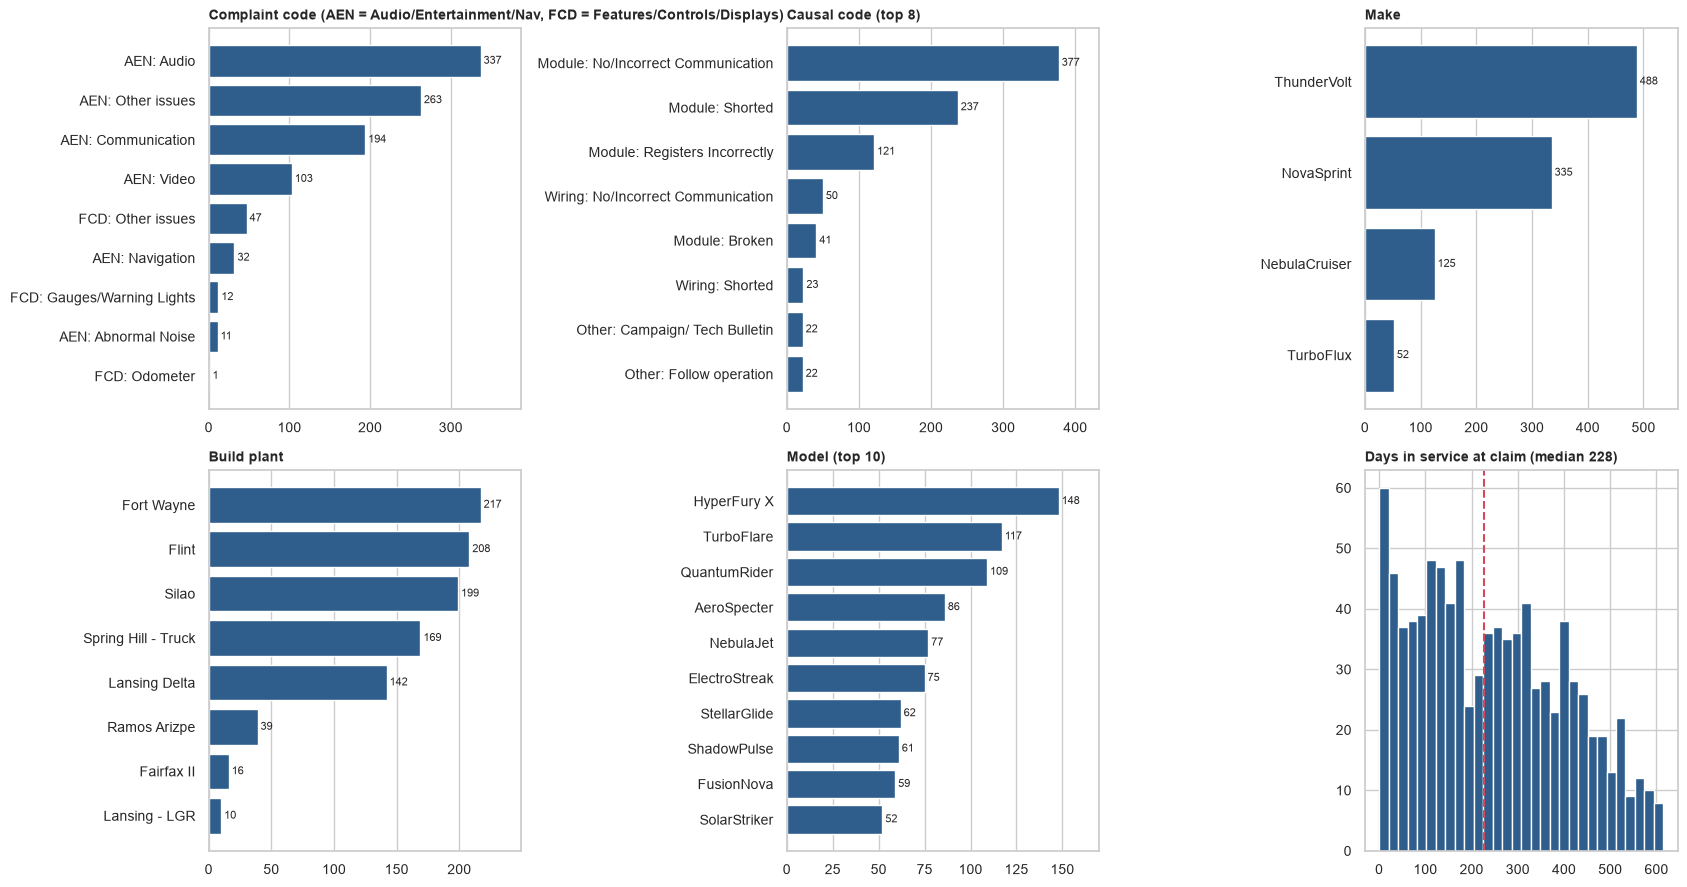

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
barh(ax[0, 0], df.complaint_short.value_counts(), 'Complaint code (AEN = Audio/Entertainment/Nav, FCD = Features/Controls/Displays)')
barh(ax[0, 1], df.cause_short.value_counts(), 'Causal code (top 8)', n=8)
barh(ax[0, 2], df.MAKE.value_counts(), 'Make')
barh(ax[1, 0], df.BUILD_PLANT_DESC.value_counts(), 'Build plant')
barh(ax[1, 1], df.MODEL.value_counts(), 'Model (top 10)')
d = df.days_in_service.dropna(); ax[1, 2].hist(d, bins=30, color=BASE); ax[1, 2].axvline(d.median(), color=ACC, ls='--')
ax[1, 2].set_title(f'Days in service at claim (median {d.median():.0f})', fontsize=10, loc='left', fontweight='bold')
plt.tight_layout(); save('01_eda_distributions.png')

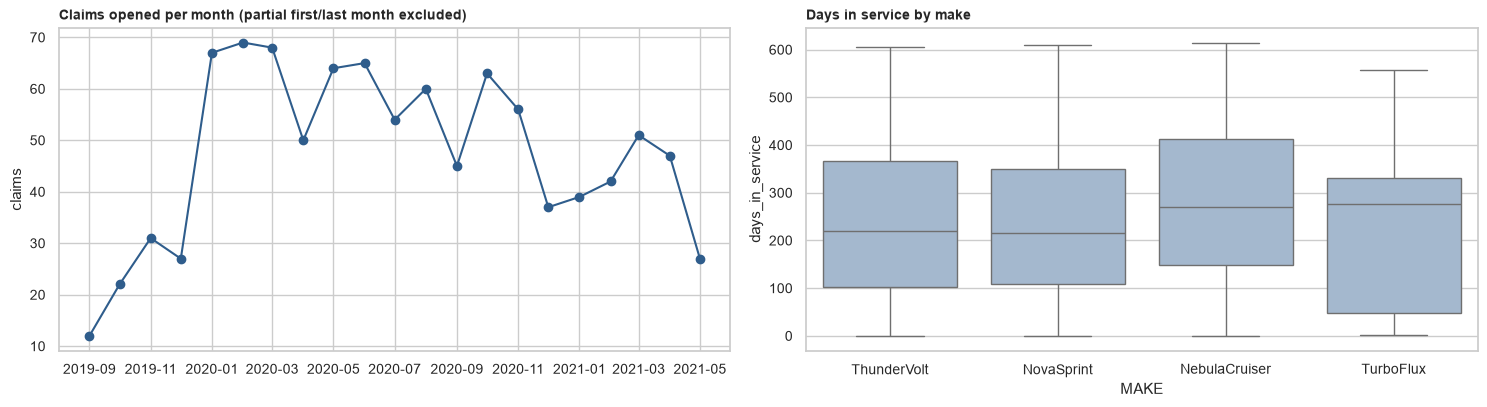

Make vs days_in_service Kruskal-Wallis p = 0.042


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
m = df.set_index('opened').resample('MS').size().iloc[1:-1]; ax[0].plot(m.index, m.values, marker='o', color=BASE)   # first/last month are partial (extract spans 27-Aug-2019 -> 1-Jun-2021)
ax[0].set_title('Claims opened per month (partial first/last month excluded)', fontsize=10, loc='left', fontweight='bold'); ax[0].set_ylabel('claims')
sns.boxplot(data=df, x='MAKE', y='days_in_service', color='#9DB7D5', ax=ax[1], order=df.MAKE.value_counts().index)
ax[1].set_title('Days in service by make', fontsize=10, loc='left', fontweight='bold')
plt.tight_layout(); save('02_eda_trend_make.png')
print('Make vs days_in_service Kruskal-Wallis p =', round(kruskal(*[g.dropna() for _, g in df.groupby('MAKE').days_in_service]).pvalue, 3))

---
## 2. Text mining — from free text to structured tags
### 2a. Identify free-text columns
A column is treated as free text when it is high-cardinality, long and sentence-like.

In [7]:
rows = []
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype) == 'str':
        s = df[c].dropna().astype(str); rows.append((c, s.nunique(), round(s.nunique()/len(df), 2), round(s.str.split().str.len().mean(), 1)))
prof = pd.DataFrame(rows, columns=['column', 'unique', 'unique_ratio', 'avg_words']).sort_values('avg_words', ascending=False)
prof['free_text'] = (prof.avg_words > 8) & (prof.unique_ratio > 0.8); display(prof.head(6))

,column,unique,unique_ratio,avg_words,free_text
3,CORRECTION_VERBATIM,951,0.95,28.6,True
2,CAUSAL_VERBATIM,943,0.94,22.4,True
4,CUSTOMER_VERBATIM,990,0.99,17.3,True
8,COMPLAINT_CD_DESC,9,0.01,3.3,False
17,cause_short,39,0.04,2.8,False
16,complaint_short,9,0.01,2.3,False


**Free-text columns:** `CUSTOMER_VERBATIM` (what the customer reported), `CAUSAL_VERBATIM` (technician diagnosis) and `CORRECTION_VERBATIM` (repair performed). They are noisy: ALL-CAPS, typos (*SCRANNED*, *INPECCION*), shorthand (*C/S, R&R, inop, SPS, TAC, DTC*), long diagnostic procedures, and **some entries are in Spanish or French**.

### 2b. Method — normalise → translate key terms → lexicon/regex entity extraction
No external model download is needed, so the notebook is fully reproducible offline. Approach:
1. **Normalise**: lower-case, strip accents, expand shorthand (`c/s`→customer states, `r&r`→replaced …).
2. **Mini ES/FR→EN lexicon** (~30 domain terms: *pantalla/écran*→screen, *negra/noir*→black, *sin sonido*→no sound …) so one English vocabulary covers all languages.
3. **Entity vocabulary** (regex per tag) grouped into the *same six entity types as the example columns* plus diagnosis, process flags and DTC status.
4. **Source-aware extraction**: customer-facing entities come from the customer text first (fallback to diagnosis, then repair); *diagnosis* tags from causal + correction; *fix* tags from correction first. This avoids mis-tagging test steps (“tested display – OK”) as failures.

In [8]:
LEX = [  # (regex, replacement) applied BEFORE punctuation is removed. Shorthand first, then ES/FR → EN.
 (r'\bc/s\b|\bc s\b|\bcs\b', 'customer states'), (r'\bcust\b', 'customer'), (r'\binop\b|\binoperable\b|\binoperatable\b', 'inoperative'),
 (r'\br ?& ?r\b|\br/r\b', 'replaced'), (r'\bw/o\b', 'without'), (r'\bw/\b', 'with'), (r"\bdoesn't\b|\bdoesnt\b", 'does not'), (r"\bwon't\b|\bwont\b", 'will not'), (r"\bcan't\b|\bcant\b", 'cannot'),
 (r'\bpantalla\b|\becran\b', 'screen'), (r'\bnegr[ao]\b|\bnoir[e]?\b', 'black'), (r'\bsin sonido\b|\bpas de son\b|\bsans son\b', 'no sound'), (r'\bsonido\b', 'sound'),
 (r'\bbocinas?\b|\bhaut[- ]parleurs?\b|\baltavoz(es)?\b', 'speaker'), (r'\bcamara\b|\bcamera\b|\bcaméra\b', 'camera'), (r'\breversa\b|\bmarche arriere\b|\bmarche arrière\b', 'reverse'),
 (r"\bse apaga\b|\bs'éteint\b|\bs'eteint\b|\bse apagan\b", 'turns off'), (r'\bno funciona\b|\bne fonctionne pas\b|\bne marche pas\b|\bno sirve\b|\bfalla\b|\bpanne\b', 'not working'),
 (r'\bcliente?\b|\bclient\b', 'customer'), (r'\breemplaz\w+|\bremplac\w+|\bcambio de\b', 'replaced'), (r'\breprogram[eé]\w*', 'reprogrammed'),
 (r'\btelefono\b|\btéléphone\b|\btelephone\b', 'phone'), (r'\bantena\b', 'antenna'), (r'\bruido\b|\bbruit\b', 'noise'), (r'\ba veces\b|\bparfois\b', 'sometimes'),
 (r'\bintermitente\b', 'intermittent'), (r'\bmanejando\b|\ben conduite\b|\ben marcha\b', 'driving'), (r'\bactualizaci[oó]n\b|\bmise [àa] jour\b', 'update'),
 (r'\bno enciende\b|\bne s.?allume pas\b', 'will not turn on'), (r'\bse congela\b|\bse traba\b', 'freezes'), (r'\bpantalla en blanco\b', 'blank screen'),
]
LEX = [(re.compile(p), r) for p, r in LEX]

def norm(s):
    """Lower-case -> strip accents -> shorthand/translation lexicon -> remove punctuation. Returns '' for missing text."""
    if pd.isna(s): return ''
    s = str(s).lower()
    for p, r in LEX: s = p.sub(r, s)
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()      # accents out (after lexicon so accented terms still match)
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9]+', ' ', s)).strip()

T = {k: df[c].map(norm) for k, c in zip(['cust', 'causal', 'corr'], TXT)}       # normalised text per source

# --- language detection by function-word voting (before translation, on raw lower-case text) ---
ES = set('el la los las de que se no con por para pantalla cliente del una esta lo al es en un su'.split())
FR = set('le les des est pas que pour avec client une sur ecran au du et ne il un la'.split())
EN = set('the and customer states to for with is not on in of was radio screen at it a'.split())
def lang(row):
    w = re.findall(r"[a-zà-ÿ]+", ' '.join(str(x).lower() for x in row if pd.notna(x)))
    sc = {'es': sum(x in ES for x in w), 'fr': sum(x in FR for x in w), 'en': sum(x in EN for x in w)}
    top = max(sc, key=sc.get); return top if sc[top] > 1.2 * sc['en'] or top == 'en' else 'en'
df['language'] = df[TXT].apply(lang, axis=1)
print(df.language.value_counts().to_string())

language
en    987
fr      9
es      4


In [9]:
# ----------------- ENTITY VOCABULARY (tag -> regex on normalised text) -----------------
GAP = r'\W+(?:\w+\W+){0,%d}'            # up to N words between two terms
def near(a, b, n=4): return rf'(?:{a}){GAP % n}(?:{b})|(?:{b}){GAP % n}(?:{a})'
FIXV = r'replac\w*|install\w*|new|swap\w*|repair\w*|clean\w*|reseat\w*|re ?seat\w*|secur\w*|re ?terminat\w*|re ?pin\w*|splic\w*|reroute\w*|tighten\w*'

VOCAB = {
 'failure_component': {   # WHAT is reported as failing (cascade: customer -> causal -> correction)
  'Radio':               r'\b(radio|head ?unit|infotainment|stereo|ihu|audio unit|audio system|entertainment system|hmi)\b',
  'Display':             r'\b(screen|display|monitor|lcd|touch ?screen)\b',
  'Controls / Buttons':  r'\b(buttons?|knobs?|touch|controls?|swc|steering wheel controls?)\b(?! module)',
  'Backup Camera':       r'\b(camera|rear vision|rvc|rear view)\b',
  'Speakers / Amplifier':r'\b(speakers?|amplifier|amp|woofer|subwoofer)\b',
  'Antenna / Coax':      r'\b(antenna|coax\w*|aerial)\b',
  'Satellite Radio (XM)':r'\b(xm|sirius\w*|satellite|satelite|sdars)\b',
  'Bluetooth / Phone':   r'\b(blue ?tooth|phone|hands ?free|pairing|paired|pair|carplay|android auto|apple)\b',
  'Navigation / GPS':    r'\b(navigation|navi|nav|gps|maps?)\b',
  'OnStar / Telematics': r'\b(onstar|on star|tcim|tcicm|telematics|telemmatics|wifi|wi fi|hotspot|4g|lte)\b',
  'USB / SD / Media':    r'\b(usb|sd card|aux|cd|disc|ipod|media)\b',
  'Wiring / Connector':  r'\b(wir(e|es|ing)|harness|connectors?|cables?|fuse|terminals?)\b',
 },
 'failure_condition_symptom': {   # HOW it fails, as experienced (cascade)
  'Inoperative':         r'\b(inoperative|dead|not working|not work|does not work|stopped working|quit working|quits working|no power|will not (come on|turn on|power|start up|boot)|not (come on|power up)|no response)\b',
  'Black Screen':        r'\b(black|blank|dark)\b',
  'No Sound':            r'\b(no (sound|audio|volume)|without sound|no sound|muted?|sound (cuts?|drops?|stops?|goes|cutting|cuts out)|no speakers?)\b',
  'Controls Unresponsive':r'\b(unresponsive|not respond\w*|no response)\b|\b(buttons?|knobs?|controls?|touch\w*)\W+(?:\w+\W+){0,3}(not|quit|stop\w*|inoperative|do not|does not|will not)\b',
  'Freezing / Lock-up':  r'\b(freez\w*|froze|frozen|lock\w* up|locks up|hang\w*|hangs|stuck|lag\w*|slow|stays? on|remains? on)\b',
  'Random Shutdown / Reboot': r'\b(reboot\w*|re boot\w*|restarts?|restarting|resets? (itself|randomly|by itself|on its own)|shuts? (itself )?off|shut ?down|turns? (itself )?off|cuts? (out|off)|power cycl\w*|loop\w*|turns off and on|on and off)\b',
  'Noise / Distortion':  r'\b(static|noise|noisy|distort\w*|crackl\w*|buzz\w*|hiss\w*|popping|garbled|skip\w*|squeal\w*)\b',
  'Signal Loss':         r'\b(?:no|lost|loss of|poor|weak|bad|drops?|dropping)\W+(?:\w+\W+){0,2}(?:signal|reception)\b|\bsignal (lost|loss|drop\w*)\b|\bno (xm|sirius)\b|\bsatellite signal\b',
  'Connection / Pairing Failure': r'\b(blue ?tooth|phone|pair\w*|wifi|hotspot|connect\w*)\W+(?:\w+\W+){0,5}(not|will not|fail\w*|unable|cannot|drop\w*|disconnect\w*|lost)\b|\b(not|unable to|cannot|fail\w*)\W+(?:\w+\W+){0,3}(pair|connect)\b|\bdisconnect\w*|\bkeeps? (trying|attempting) to connect',
  'Erratic Behaviour':   r'\b(erratic\w*|random\w*|flicker\w*|flash\w*|switches? (by itself|on its own)|changes? (by itself|on its own)|by itself|on its own|ghost\w*|jumps?|wrong)\b',
  'Error Message':       r'\b(error|message|warning|prompt|fault message|service (radio|system))\b',
  'Volume Issue':        r'\bvolume\b',
 },
 'diagnosis': {     # technician FINDINGS (union over causal + correction)
  'Internal Fault':      r'\binternal\w*\b',
  'Malfunction':         r'\b(malfunction\w*|faulty|defective)\b',
  'Shorted':             r'\b(shorted|shorting|internal\w* short\w*|short circuit(ed)?|found (a )?short)\b',
  'Lost Communication':  r'\b(no|lost|loss of|loss)\W+(?:\w+\W+){0,1}communication\b|\bcommunication (loss|lost|error|fault|failure)\b|\b(u\d{4})\b|\bethernet\b|\bdata link\b|\bcan bus\b|\blin bus\b|\bno comm\w*|\bnot communicating\b|\bunable to communicate\b|\blost comm\w*',
  'Software Fault':      r'\b(software (issue|concern|glitch|problem|fault|bug|error|corrupt\w*)|corrupt\w*|glitch|outdated software|software (is )?out ?dated)\b',
  'Wiring Fault':        near(r'wir(?:e|es|ing)|harness|connectors?|pins?|terminals?|cables?|coax|ground', r'damag\w*|chafe\w*|pinch\w*|corrod\w*|loose|open|broken|cut|fray\w*|high resistance|bent|backed out|poor|melt\w*|burn\w*', 4),
  'Water / Moisture':    r'\b(water|moisture|wet|liquid|spill\w*|corroded)\b',
  'Physical Damage':     r'\b(cracked|crack|broken|worn|damaged|bent)\b(?!\W+(?:\w+\W+){0,2}(?:wire|wiring|harness|connector|cable|pin))',
  'No Fault Found':      r'\b(unable|could not|cannot|not able|did not|didnt)\W+(?:\w+\W+){0,2}(duplicate|verify|replicate|reproduce|find)\b|\bno (fault|problem|concern|issue|trouble)s? (found|detected|present)\b|\bnff\b|\bntf\b|\bno trouble found\b|\bnot duplicated\b|\bcould not duplicate\b|\bconcern (is )?not present\b',
 },
 'trigger': {       # WHEN / what provokes it (cust + causal union)
  'When Reversing':      r'\b(revers\w*|backing up|backing|in r)\b',
  'At Start-up':         r'\b(start ?up|startup|starts? (up|the (vehicle|car|truck))|when (he|she|customer) starts?|upon start\w*|after start\w*|on start\w*|ignition (on|cycle)|turn\w* (the )?(vehicle|car|truck|key|ignition) on|cold start|remote start|first start)\b',
  'After Software Update': r'\b(after|since|following)\W+(?:\w+\W+){0,3}(updat\w*|upgrad\w*|software|reprogram\w*|flash\w*)\b',
  'During Phone Call':   r'\b(phone call|during (a )?call|on (a )?call|making calls?|receiving calls?|incoming call|outgoing call|calls? (drop|cut|disconnect)\w*)\b',
  'When Changing Source': r'\b(chang\w*|switch\w*)\W+(?:\w+\W+){0,2}(source|station|band|am|fm|xm|input|mode)\b|\bsource (change|switch)\b',
 },
 'context': {       # additional circumstances (cust + causal union)
  'Intermittent':        r'\b(intermittent\w*|random\w*|at times|sometimes|occasional\w*|off and on|on and off|comes? and goes?|from time to time|periodic\w*|inconsistent\w*|every now and then)\b',
  'While Driving':       r'(?<!test )\b(while|when|during|as|after)\W+(?:\w+\W+){0,2}driving\b|(?<!test )\bdriving (down|on|at)\b|\bat (high )?speed\b|\bon (the )?(highway|freeway)\b',
  'Cold / Hot Weather':  r'\b(cold|hot|heat|temperature|winter|summer|warm up|freezing weather)\b',
  'Rain / Moisture':     r'\b(rain|wet|water|moisture|humid\w*|car ?wash)\b',
  'Clears After Ignition Cycle': r'\b(until|unless|after)\W+(?:\w+\W+){0,4}(turned|turn|cycle\w*|shut|key)\W+(?:\w+\W+){0,3}(off|back on|restart\w*)\b|\bturned off (then|and) (back )?on\b',
 },
 'fix_component': {   # WHAT was touched to repair (cascade: correction -> causal)
  'Radio':               r'\b(radio|head ?unit|infotainment|stereo|ihu|audio unit|rcm)\b',
  'SPS':                 r'\b(sps|service programming|techline)\b',
  'USB':                 r'\b(usb|file transfer|flash drive)\b',
  'Display':             near(FIXV, r'screen|display|monitor', 3),
  'Camera':              near(FIXV, r'camera', 3),
  'Antenna / Coax':      near(FIXV, r'antenna|coax\w*|aerial', 3),
  'Wiring / Connector':  near(FIXV, r'wir(?:e|es|ing)|harness|connector|cable|terminal|fuse|ground', 3),
  'Amplifier / Speaker': near(FIXV, r'amplifier|amp|speakers?', 3),
  'Telematics Module':   near(FIXV, r'tcim|tcicm|telematics|onstar', 3),
 },
 'fix_condition': {   # WHAT was done (cascade: correction -> causal)
  'Replaced':            r'\b(replac\w*|swap\w*|installed (a |the )?(new|replacement)|new (radio|unit|module))\b',
  'Programmed':          r'\b(program\w*|reprogram\w*|re ?flash\w*|flash\w*|updat\w*|upgrad\w*|software|calibrat\w*|set ?up)\b',
  'Repaired':            r'\b(repair\w*|fix\w*|clean\w*|re ?terminat\w*|re ?pin\w*|re ?seat\w*|re ?secure\w*|splic\w*|tighten\w*|re ?rout\w*|reposition\w*|adjust\w*)\b',
  'Reset / Codes Cleared': r'\b(reset|cleared|clear (all )?(codes|dtcs?)|battery disconnect\w*|hard reset|reboot\w*)\b',
 },
 'process': {   # service-process flags (union over all three texts)
  'TAC / Engineering Contacted': r'\b(tac|techline|engineering|fse|field service engineer)\b',
  'TSB / Campaign Referenced':   r'\b(tsb|campaign|recall)\b|\bbulletin\b(?!s? (found|none))',
  'Repeat Visit':                r'\b(returned|return visit|second (time|visit)|third time|repeat\w*|came back|previous(ly)? (repair|visit)|prior repair|multiple visits?)\b',
  'Loan Vehicle Provided':       r'\b(loan(er)? vehicle|ctp|rental)\b',
 },
}
DEFAULT = {'trigger': 'No Additional Functionality', 'context': 'No Additional Context'}   # same wording as the provided example rows
# type -> source groups. Within a group a tag is kept if found in ANY source; groups are tried in order and the first group yielding a tag wins (cascade).
SPEC = {'failure_component': [['cust'], ['causal'], ['corr']], 'failure_condition_symptom': [['cust', 'causal'], ['corr']],
        'diagnosis': [['causal', 'corr']], 'trigger': [['cust', 'causal']], 'context': [['cust', 'causal']],
        'fix_component': [['corr'], ['causal']], 'fix_condition': [['corr'], ['causal']], 'process': [['cust', 'causal', 'corr']]}

def hits(vocab, text): return pd.DataFrame({t: text.str.contains(p, regex=True) for t, p in vocab.items()})
def extract(etype):
    """Boolean tag matrix (rows x tags): union inside a source group, cascade across groups."""
    M = None
    for grp in SPEC[etype]:
        H = hits(VOCAB[etype], T[grp[0]])
        for src in grp[1:]: H = H | hits(VOCAB[etype], T[src])
        M = H if M is None else M.where(M.any(axis=1), H, axis=0)
    return M
def to_lists(M, default='Unspecified'): return M.apply(lambda r: [t for t, v in r.items() if v] or [default], axis=1)

M = {e: extract(e) for e in VOCAB}
df['tag_failure_component'] = to_lists(M['failure_component'])
df['tag_symptom'] = to_lists(M['failure_condition_symptom'])
df['tag_diagnosis'] = to_lists(M['diagnosis'], default='None Recorded')
df['tag_failure_condition'] = (df.tag_symptom + df.tag_diagnosis).map(lambda l: [t for t in dict.fromkeys(l) if t not in ('Unspecified', 'None Recorded')] or ['Unspecified'])  # symptoms + findings, like the example column
df['tag_trigger'] = to_lists(M['trigger'], DEFAULT['trigger']); df['tag_additional_context'] = to_lists(M['context'], DEFAULT['context'])
fc = M['fix_condition'].copy(); fc.loc[fc[['Replaced', 'Programmed', 'Repaired']].any(axis=1), 'Reset / Codes Cleared'] = False   # 'reset' only counts when it is the *only* action
df['tag_fix_component'] = to_lists(M['fix_component']); df['tag_fix_condition'] = to_lists(fc)
df['tag_process'] = to_lists(M['process'], 'None Recorded')

# --- DTC (fault-code) status: raw codes are masked in this extract (0 matches of P/U/B/C-codes), so we classify what the text says about codes ---
RAW_CODE = r'\b[pubc][0-9]{4}\b'
NO_DTC = r'\b(no|none|zero|without)\W+(?:\w+\W+){0,2}(dtcs?|codes?)\b|\b(dtcs?|codes?)\W+(?:\w+\W+){0,2}(none|not found|not set|not stored|not present)\b'
ALL = T['cust'] + ' | ' + T['causal'] + ' | ' + T['corr']
df['dtc_status'] = np.select([ALL.str.contains(NO_DTC), ALL.str.contains(r'\b(dtcs?|codes?)\b')], ['No DTC Found', 'DTC Referenced'], 'Not Mentioned')
print('Raw DTC strings found:', ALL.str.contains(RAW_CODE).sum(), '|', df.dtc_status.value_counts().to_dict())
print('\nShare of rows with at least one specific tag:'); print({c: f'{(df[c].map(lambda l: l[0] not in ("Unspecified","None Recorded"))).mean():.0%}' for c in ['tag_failure_component', 'tag_failure_condition', 'tag_fix_component', 'tag_fix_condition']})

Raw DTC strings found: 0 | {'Not Mentioned': 426, 'DTC Referenced': 394, 'No DTC Found': 180}

Share of rows with at least one specific tag:
{'tag_failure_component': '100%', 'tag_failure_condition': '90%', 'tag_fix_component': '98%', 'tag_fix_condition': '98%'}


### 2c. Validation against the five example-tagged rows
The provided examples act as a tiny gold set (n = 5 — a sanity check, **not** a statistically meaningful accuracy estimate). Gold synonyms are mapped (`Audio Unit`/`Radio Module` → Radio, `Controls Irresponsive` → Controls Unresponsive; `Black Screen`, `Inoperative` are shared names). Evaluation is set-based per row (precision = share of my tags that are in gold; recall = share of gold tags I found).

In [10]:
ALIAS = {'Audio Unit': 'Radio', 'Radio Module': 'Radio', 'Controls Irresponsive': 'Controls Unresponsive', 'OnStar': 'OnStar / Telematics'}
PAIRS = {'Trigger': 'tag_trigger', 'Failure Component': 'tag_failure_component', 'Failure Condition': 'tag_failure_condition', 'Failure Condition (symptoms only)': 'tag_symptom',
         'Additional Context': 'tag_additional_context', 'Fix Component': 'tag_fix_component', 'Fix Condition': 'tag_fix_condition'}
rec = []
for eid in gold.index:
    for g, m in PAIRS.items():
        G = {ALIAS.get(x, x) for x in gold.loc[eid, g.replace(' (symptoms only)', '')]}; P = set(df.loc[df['Event id'] == eid, m].iloc[0])
        rec.append(dict(event=eid, field=g, gold=sorted(G), mine=sorted(P), tp=len(G & P), n_gold=len(G), n_mine=len(P)))
V = pd.DataFrame(rec); display(V[['event', 'field', 'gold', 'mine']].head(12))
S = V.groupby('field')[['tp', 'n_gold', 'n_mine']].sum(); S['precision'] = (S.tp/S.n_mine).round(2); S['recall'] = (S.tp/S.n_gold).round(2)
S['F1'] = (2*S.precision*S.recall/(S.precision+S.recall)).round(2); display(S)
tot = V[~V.field.str.contains('symptoms only')][['tp', 'n_gold', 'n_mine']].sum(); print(f'Overall (micro): precision {tot.tp/tot.n_mine:.2f} | recall {tot.tp/tot.n_gold:.2f}')

,event,field,gold,mine
0,D-14801,Trigger,[No Additional Functionality],[No Additional Functionality]
1,D-14801,Failure Component,"[Display, Radio]","[Display, Radio]"
2,D-14801,Failure Condition,"[Black Screen, Controls Unresponsive]","[Inoperative, Internal Fault, Lost Communication, No Fault Found, ..."
3,D-14801,Failure Condition (symptoms only),"[Black Screen, Controls Unresponsive]","[Inoperative, Random Shutdown / Reboot]"
4,D-14801,Additional Context,[No Additional Context],[No Additional Context]
5,D-14801,Fix Component,"[Radio, SPS]","[Radio, SPS, USB]"
6,D-14801,Fix Condition,"[Programmed, Replaced]","[Programmed, Replaced]"
7,D-14869,Trigger,[No Additional Functionality],[No Additional Functionality]
8,D-14869,Failure Component,"[Display, Radio]",[Radio]
9,D-14869,Failure Condition,"[Black Screen, Inoperative, No Sound]","[Black Screen, Connection / Pairing Failure, Inoperative, Lost Com..."


,tp,n_gold,n_mine,precision,recall,F1
field,,,,,,
Additional Context,3,5,5,0.60,0.60,0.60
Failure Component,7,9,8,0.88,0.78,0.83
Failure Condition,6,9,18,0.33,0.67,0.44
Failure Condition (symptoms only),4,9,12,0.33,0.44,0.38
Fix Component,6,8,8,0.75,0.75,0.75
Fix Condition,6,8,9,0.67,0.75,0.71
Trigger,5,5,5,1.00,1.00,1.00


Overall (micro): precision 0.62 | recall 0.75


*Reading the validation:* trigger (P/R 1.0), failing component (0.88 / 0.78) and fix tags (0.67–0.75) match the examples well. **`Failure Condition` is the weakest field** (precision 0.33, recall 0.67; symptoms-only recall 0.44): the example labels often come from deep inside the repair narrative (e.g. *Black Screen* inferred from a technician's description), and our output additionally records technician findings (*Internal Fault, Lost Communication*) that the examples omit. With n = 5 these are directional checks only; a larger labelled set is the first improvement (see conclusions).

### 2d. Categorise “type of issue”
Two complementary, human-readable groupings are derived from the mined tags:
* **`issue_category`** – *what kind of failure is it?* (Component Failure, Electrical/Wiring, Communication/Network, Software/Calibration, Assembly/Build Quality, No Fault Found). **The coded causal field drives the category when informative; mined text tags are used to resolve vague codes (`Registers Incorrectly`, `Other-*`, missing)** — so the logic is auditable.
* **`symptom_area`** – *which customer-facing function?* (Camera, Navigation, XM, Phone/Bluetooth, Display, …).

In [11]:
ASSEMBLY_SYS = {'Fastener', 'Surface (interior)', 'Interface (Gasket; Seal; Hose; Weld..)', 'Rotating Part'}
ASSEMBLY_MODE = {'Not Clipped', 'Routing', 'Wrong Part', 'Foreign Material', 'Loose', 'Alignment/Adjustment', 'Out of balance', 'Warped/Wavy/Wrinkled', 'Off-Colour', 'Noise during operation'}
SOFT_MODE = {'Incorrect Version', 'Campaign/ Tech Bulletin', 'No trouble found - adjusted / reprogrammed'}
ELEC_MODE = {'Poor Contact', 'Discharge'}
HW_MODE = {'Shorted', 'Broken', 'Worn/Stripped', 'Damaged/Cracked'}

def categorize(r):
    sys_, mode, dg, fx, tr = r.cause_system, r.cause_mode, set(r.tag_diagnosis), set(r.tag_fix_condition), set(r.tag_trigger)
    hw_fix = bool(fx & {'Replaced', 'Repaired'})
    if sys_ in ASSEMBLY_SYS or mode in ASSEMBLY_MODE: return 'Assembly / Build Quality'
    if mode == 'Not Duplicated' or ('No Fault Found' in dg and not hw_fix and 'Programmed' not in fx): return 'No Fault Found / Not Duplicated'
    if mode in SOFT_MODE or 'Software Fault' in dg or 'After Software Update' in tr or fx == {'Programmed'}: return 'Software / Calibration'
    if sys_ == 'Wiring/Electrical/Sensors' or mode in ELEC_MODE: return 'Electrical / Wiring'
    if 'Communication' in mode: return 'Communication / Network Fault'
    if mode in HW_MODE: return 'Component Failure (internal)'
    # vague code (Registers Incorrectly / Other-Follow operation / Unknown): let the mined text decide
    if 'Wiring Fault' in dg: return 'Electrical / Wiring'
    if 'Lost Communication' in dg: return 'Communication / Network Fault'
    if dg & {'Internal Fault', 'Shorted', 'Malfunction', 'Physical Damage'} or hw_fix: return 'Component Failure (internal)'
    return 'Other / Unclassified'
df['issue_category'] = df.apply(categorize, axis=1)

AREA = [('Backup Camera', 'Camera / Rear Vision'), ('Navigation / GPS', 'Navigation'), ('Satellite Radio (XM)', 'Satellite Radio (XM)'), ('Bluetooth / Phone', 'Phone / Bluetooth'),
        ('OnStar / Telematics', 'OnStar / Telematics'), ('USB / SD / Media', 'USB / SD / Media'), ('Speakers / Amplifier', 'Speakers / Amplifier')]
def area(r):
    c = set(r.tag_failure_component)
    for tag, name in AREA:
        if tag in c: return name
    if 'Display' in c or 'Black Screen' in r.tag_symptom: return 'Display / Screen'
    if 'Controls / Buttons' in c: return 'Controls / Buttons'
    return 'Radio / Head Unit (general)'
df['symptom_area'] = df.apply(area, axis=1)
CATS = df.issue_category.value_counts().index.tolist()
display(pd.concat([df.issue_category.value_counts().rename('events'), (df.issue_category.value_counts(normalize=True)*100).round(1).rename('%')], axis=1))
display(pd.crosstab(df.cause_mode, df.issue_category).loc[lambda x: x.sum(axis=1) >= 8])

,events,%
issue_category,,
Component Failure (internal),382,38.2
Communication / Network Fault,372,37.2
Software / Calibration,121,12.1
Electrical / Wiring,96,9.6
Assembly / Build Quality,26,2.6
No Fault Found / Not Duplicated,3,0.3


issue_category,Assembly / Build Quality,Communication / Network Fault,Component Failure (internal),Electrical / Wiring,No Fault Found / Not Duplicated,Software / Calibration
cause_mode,,,,,,
Broken,3,0,37,0,1,3
Campaign/ Tech Bulletin,0,0,0,0,0,22
Damaged/Cracked,1,0,8,0,0,0
Discharge,0,0,0,9,0,0
Follow operation,0,5,14,2,0,1
No trouble found - adjusted / reprogrammed,0,0,0,0,0,21
No/Incorrect Communication,0,351,0,45,0,31
Poor Contact,0,0,0,10,0,1
Registers Incorrectly,0,14,93,10,0,16


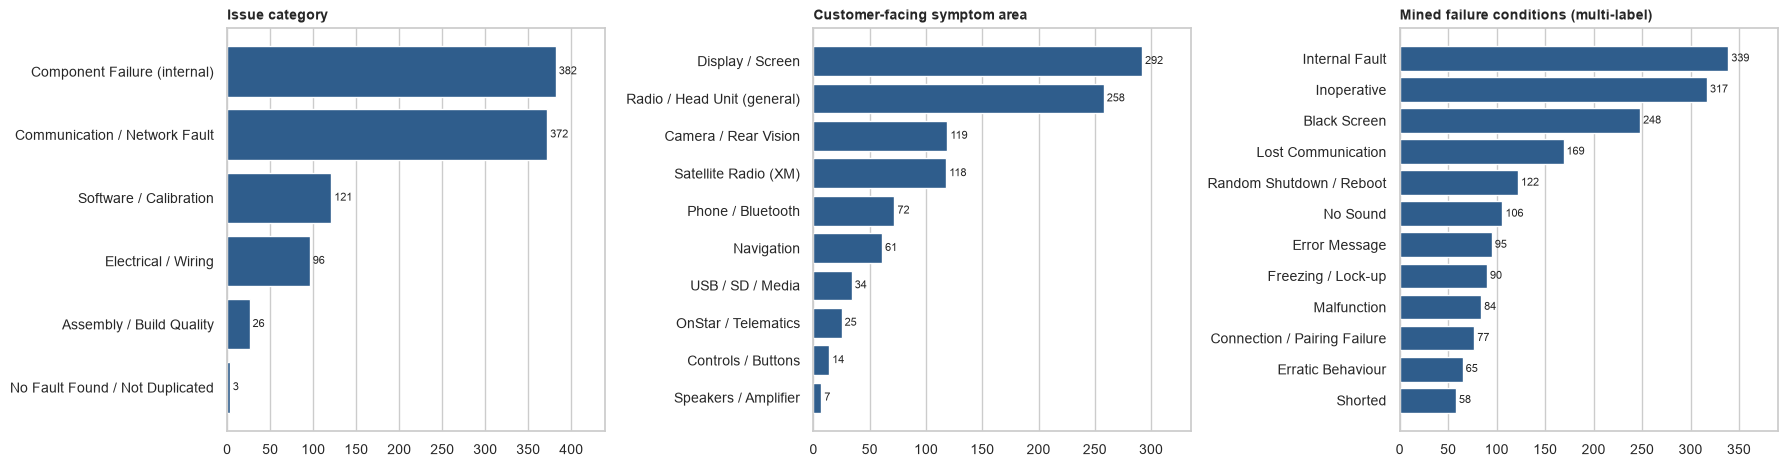

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
barh(ax[0], df.issue_category.value_counts(), 'Issue category', n=8)
barh(ax[1], df.symptom_area.value_counts(), 'Customer-facing symptom area', n=10)
barh(ax[2], df.tag_failure_condition.explode().loc[lambda x: ~x.isin(['Unspecified'])].value_counts(), 'Mined failure conditions (multi-label)', n=12)
plt.tight_layout(); save('03_categories.png')

---
## 3. Insights, trends and root causes
### 3a. Patterns — what fails most often?

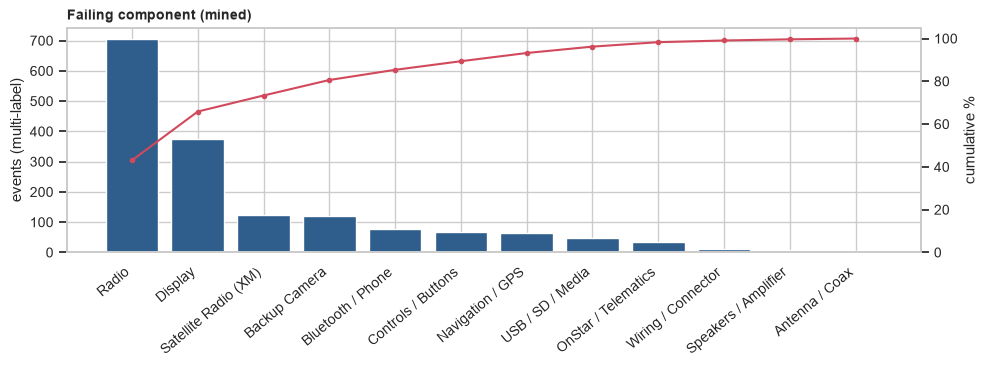

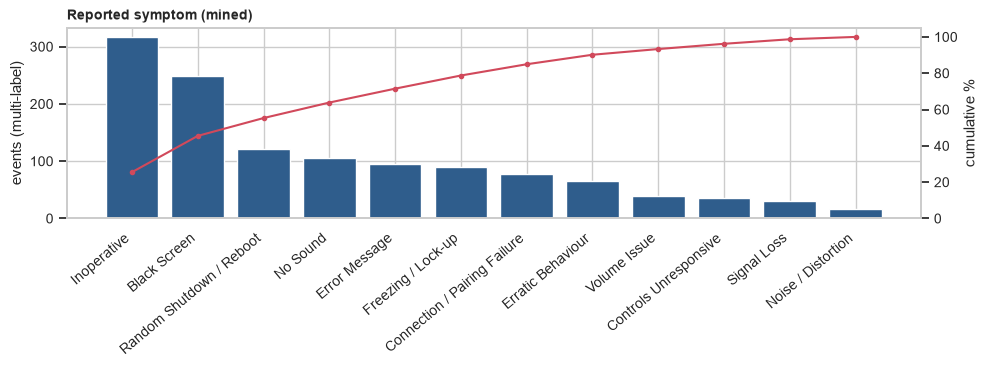

{'Radio': '71%', 'Display': '37%', 'Satellite Radio (XM)': '12%', 'Backup Camera': '12%', 'Inoperative': '32%', 'Black Screen': '25%', 'Random Shutdown / Reboot': '12%', 'No Sound': '11%'}
Fix pattern share: {'Programmed+Replaced': 0.592, 'Replaced': 0.214, 'Programmed': 0.081, 'Programmed+Repaired+Replaced': 0.07}
DTC status: {'Not Mentioned': 0.426, 'DTC Referenced': 0.394, 'No DTC Found': 0.18}
Complaint-code vs mined symptom_area agreement table:


symptom_area,Camera / Rear Vision,Controls / Buttons,Display / Screen,Navigation,OnStar / Telematics,Phone / Bluetooth,Radio / Head Unit (general),Satellite Radio (XM),Speakers / Amplifier,USB / SD / Media
complaint_type,,,,,,,,,,
Abnormal Noise,1,1,2,0,0,4,2,1,0,0
Audio,28,5,94,9,3,17,121,50,4,6
Communication,14,2,57,11,12,27,36,27,1,7
Gauges/Warning Lights,2,2,3,0,1,0,3,0,0,1
Navigation,1,0,0,23,0,1,3,1,0,3
Odometer,0,0,0,1,0,0,0,0,0,0
Other issues,44,2,84,13,7,22,85,34,2,17
Video,29,2,52,4,2,1,8,5,0,0


In [13]:
def pareto(series, title, n=12, fname=None):
    vc = series.explode().loc[lambda x: ~x.isin(['Unspecified', 'None Recorded'])].value_counts().head(n); cum = vc.cumsum()/vc.sum()*100
    fig, ax = plt.subplots(figsize=(10, 3.8)); ax.bar(vc.index, vc.values, color=BASE); ax.set_title(title, loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel('events (multi-label)'); plt.setp(ax.get_xticklabels(), rotation=40, ha='right'); ax2 = ax.twinx(); ax2.plot(vc.index, cum, color=ACC, marker='o', ms=3); ax2.set_ylim(0, 105); ax2.set_ylabel('cumulative %'); ax2.grid(False)
    plt.tight_layout(); save(fname) if fname else plt.show(); return vc
top_comp = pareto(df.tag_failure_component, 'Failing component (mined)', fname='04_pareto_component.png')
top_cond = pareto(df.tag_symptom, 'Reported symptom (mined)', fname='05_pareto_symptom.png')
n = len(df); print({k: f'{v/n:.0%}' for k, v in {**top_comp.head(4).to_dict(), **top_cond.head(4).to_dict()}.items()})
print('Fix pattern share:', df.tag_fix_condition.map(lambda l: '+'.join(sorted(l))).value_counts(normalize=True).head(4).round(3).to_dict())
print('DTC status:', df.dtc_status.value_counts(normalize=True).round(3).to_dict())
print('Complaint-code vs mined symptom_area agreement table:'); display(pd.crosstab(df.complaint_type, df.symptom_area))

### 3b. Trends over time and significant changes

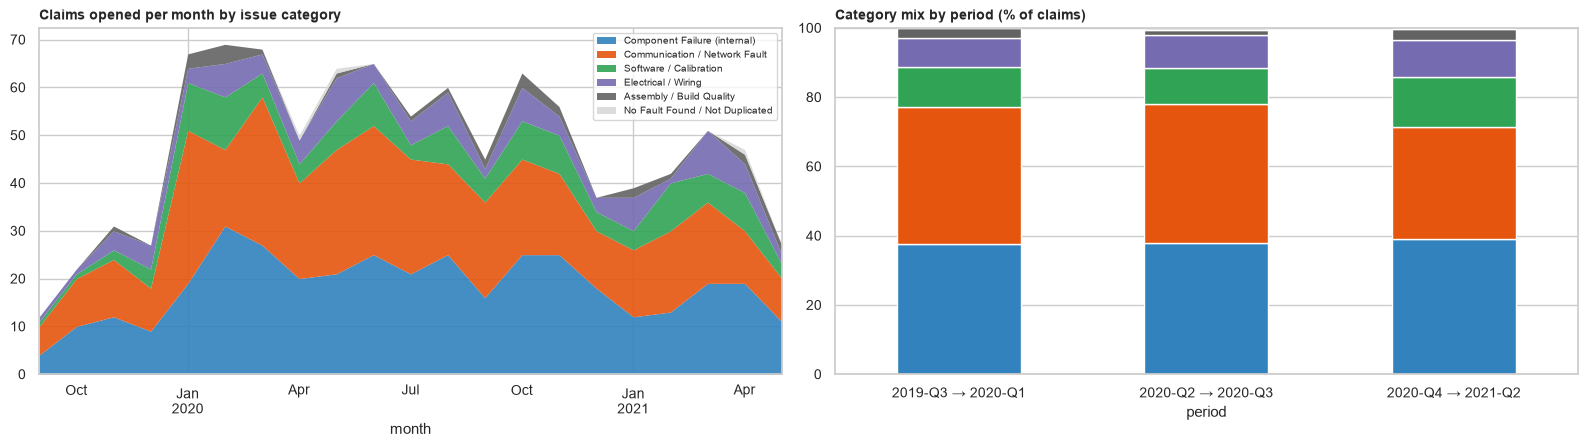

Category mix vs period: chi2 p = 0.302


,category,first_%,last_%,p,delta_pp
1,Communication / Network Fault,39.799,32.231,0.052,-7.568
5,No Fault Found / Not Duplicated,0.000,0.275,1.000,0.275
4,Assembly / Build Quality,3.010,3.306,1.000,0.296
0,Component Failure (internal),37.458,39.118,0.721,1.660
3,Electrical / Wiring,8.361,10.744,0.368,2.383
2,Software / Calibration,11.371,14.325,0.313,2.954


Months with |z|>1.5 in monthly volume: {Timestamp('2019-09-01 00:00:00'): -2.11, Timestamp('2019-10-01 00:00:00'): -1.52}


period,2019-Q3 → 2020-Q1,2020-Q2 → 2020-Q3,2020-Q4 → 2021-Q2
tag_failure_component,,,
Radio,43.4,42.0,43.7
Display,21.1,23.3,23.6
Satellite Radio (XM),9.7,6.4,6.8
Backup Camera,6.9,8.8,6.0
Bluetooth / Phone,4.4,5.1,4.7
Controls / Buttons,3.6,3.7,4.7


In [14]:
df['month'] = df.opened.dt.to_period('M').dt.to_timestamp()
df['period'] = pd.cut(df.opened, [pd.Timestamp('2019-01-01'), pd.Timestamp('2020-03-31'), pd.Timestamp('2020-09-30'), pd.Timestamp('2021-06-30')],
                      labels=['2019-Q3 → 2020-Q1', '2020-Q2 → 2020-Q3', '2020-Q4 → 2021-Q2'])   # three roughly equal-volume windows
mc = pd.crosstab(df.month, df.issue_category).reindex(columns=CATS).iloc[1:-1]   # drop partial first/last month
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
mc.plot.area(ax=ax[0], colormap='tab20c', alpha=.9, linewidth=0); ax[0].set_title('Claims opened per month by issue category', loc='left', fontsize=10, fontweight='bold'); ax[0].legend(fontsize=7, loc='upper right')
pp = pd.crosstab(df.period, df.issue_category, normalize='index').reindex(columns=CATS)*100
pp.plot.bar(stacked=True, ax=ax[1], colormap='tab20c', rot=0); ax[1].set_title('Category mix by period (% of claims)', loc='left', fontsize=10, fontweight='bold'); ax[1].legend().remove()
plt.tight_layout(); save('06_trend_category.png')
chi, p, _, _ = chi2_contingency(pd.crosstab(df.period, df.issue_category)); print(f'Category mix vs period: chi2 p = {p:.3f}')

# per-category change between first and last window (2x2 chi-square) + monthly spike detector
ct = pd.crosstab(df.period, df.issue_category); first, last = ct.index[0], ct.index[-1]; rows = []
for c in CATS:
    a, b = ct.loc[first, c], ct.loc[last, c]; t = chi2_contingency([[a, ct.loc[first].sum()-a], [b, ct.loc[last].sum()-b]])[1]
    rows.append((c, a/ct.loc[first].sum()*100, b/ct.loc[last].sum()*100, t))
chg = pd.DataFrame(rows, columns=['category', 'first_%', 'last_%', 'p']).assign(delta_pp=lambda d: d['last_%']-d['first_%']).round(3).sort_values('delta_pp'); display(chg)
mm = df.set_index('opened').resample('MS').size().iloc[1:-1]; z = (mm - mm.mean())/mm.std(); print('Months with |z|>1.5 in monthly volume:', z[abs(z) > 1.5].round(2).to_dict())
# component trend: which mined components are growing / shrinking
ex = df.explode('tag_failure_component').reset_index(drop=True); cm = (pd.crosstab(ex.tag_failure_component, ex.period, normalize='columns')*100).round(1)
display(cm.loc[top_comp.head(6).index])

**Caution on interpretation.** The extract has no production/sales denominators, so changes are *shares of claims*, not failure *rates*. Recent months are also right-censored (vehicles have not had time to fail), which depresses late-2021 counts independent of quality.

### 3c. Segment effects — plant, make, model, build timing

BUILD_PLANT_DESC   vs issue_category: chi2 p = 0.490, Cramér V = 0.08
MAKE               vs issue_category: chi2 p = 0.148, Cramér V = 0.08
MODEL              vs issue_category: chi2 p = 0.067, Cramér V = 0.11


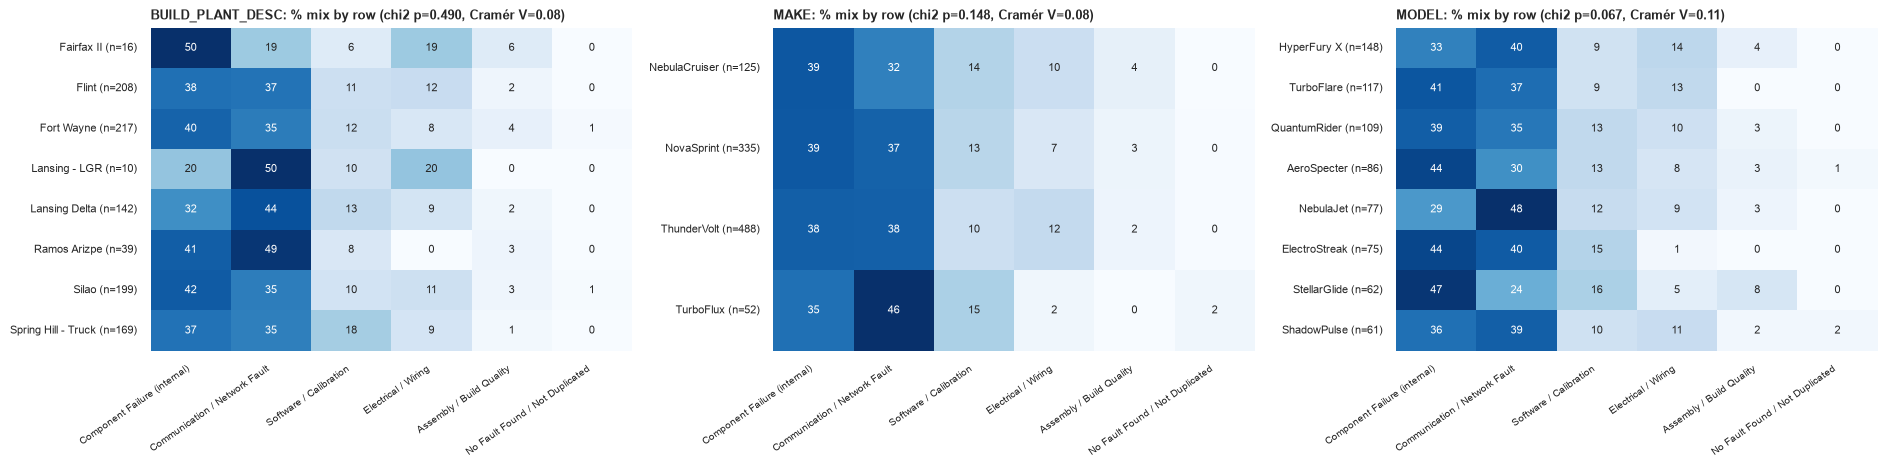

Plant x symptom_area


lift   n
BUILD_PLANT_DESC    symptom_area                         
Silao               Navigation                   1.57  19
Lansing Delta       Radio / Head Unit (general)  1.34  49
                    Satellite Radio (XM)         1.25  21
Fort Wayne          Phone / Bluetooth            1.22  19
Spring Hill - Truck Camera / Rear Vision         1.19  24
Flint               Camera / Rear Vision         1.13  28

Model x issue_category


,,lift,n
MODEL,issue_category,,
HyperFury X,Electrical / Wiring,1.41,20
TurboFlare,Electrical / Wiring,1.34,15
NebulaJet,Communication / Network Fault,1.29,37
SolarStriker,Communication / Network Fault,1.24,24
StellarGlide,Component Failure (internal),1.22,29
AeroSpecter,Component Failure (internal),1.16,38


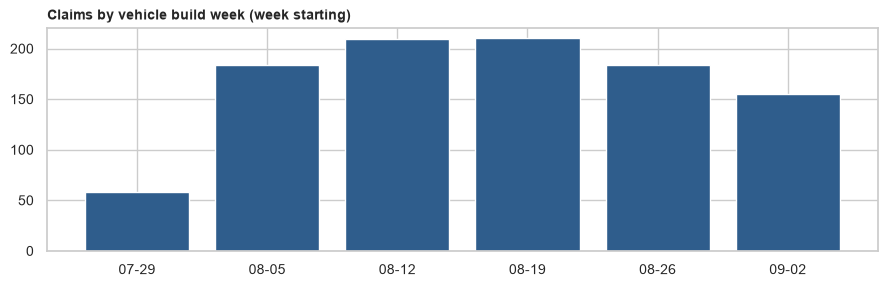

In [15]:
def assoc(col, rowsel=None):
    ct = pd.crosstab(df[col], df.issue_category).reindex(columns=CATS)
    if rowsel is not None: ct = ct.loc[rowsel]
    chi, p, _, _ = chi2_contingency(ct); v = np.sqrt(chi/(ct.values.sum()*(min(ct.shape)-1))); return ct, p, v
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for a, col, sel in zip(ax, ['BUILD_PLANT_DESC', 'MAKE', 'MODEL'], [None, None, df.MODEL.value_counts().head(8).index]):
    ct, p, v = assoc(col, sel); ct.index = [f'{i} (n={k})' for i, k in zip(ct.index, ct.sum(axis=1))]; sns.heatmap(ct.div(ct.sum(axis=1), axis=0)*100, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=a, annot_kws={'size': 8})
    print(f'{col:18s} vs issue_category: chi2 p = {p:.3f}, Cramér V = {v:.2f}'); a.set_title(f'{col}: % mix by row (chi2 p={p:.3f}, Cramér V={v:.2f})', fontsize=9, loc='left', fontweight='bold'); a.set_ylabel(''); a.set_xlabel('')
    plt.setp(a.get_xticklabels(), rotation=35, ha='right', fontsize=7); plt.setp(a.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout(); save('07_segment_heatmaps.png')

# which segment x symptom combinations are over-represented? (lift = share within segment / overall share; n>=15)
def lift_table(seg, target, minn=15, top=6):
    ct = pd.crosstab(df[seg], df[target]); lift = ct.div(ct.sum(axis=1), axis=0).div(ct.sum()/ct.values.sum(), axis=1)
    out = lift.stack().rename('lift').to_frame().join(ct.stack().rename('n')).query('n >= @minn').sort_values('lift', ascending=False).head(top); return out.round(2)
print('Plant x symptom_area'); display(lift_table('BUILD_PLANT_DESC', 'symptom_area'))
print('Model x issue_category'); display(lift_table('MODEL', 'issue_category'))
# build-week concentration (claims by build week)
bw = df.groupby(df.build.dt.to_period('W').dt.start_time).size(); plt.figure(figsize=(9, 3)); plt.bar(bw.index.astype(str).str[5:], bw.values, color=BASE); plt.title('Claims by vehicle build week (week starting)', loc='left', fontsize=10, fontweight='bold'); plt.tight_layout(); save('08_build_week.png')

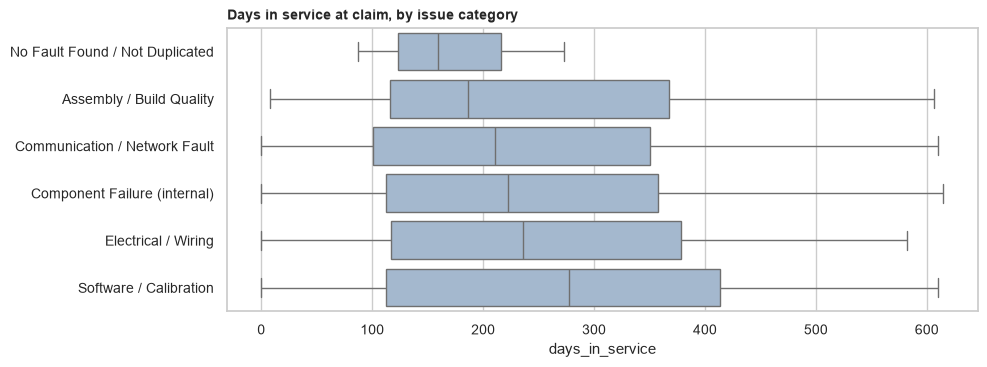

Kruskal-Wallis p = 0.349
                                 count  median   mean
issue_category                                       
Assembly / Build Quality            26   186.0  231.0
Communication / Network Fault      334   211.0  232.0
Component Failure (internal)       358   222.0  240.0
Electrical / Wiring                 91   236.0  250.0
No Fault Found / Not Duplicated      3   159.0  173.0
Software / Calibration             112   277.0  272.0
Share of claims inside first 90 days of service: 20% | first 180: 39%


In [16]:
# time-to-failure by category (days between in-service and claim; right-censored, 7.6% invalid dates excluded)
order = df.groupby('issue_category').days_in_service.median().sort_values().index
plt.figure(figsize=(10, 3.8)); sns.boxplot(data=df, y='issue_category', x='days_in_service', order=order, color='#9DB7D5'); plt.title('Days in service at claim, by issue category', loc='left', fontsize=10, fontweight='bold'); plt.ylabel(''); plt.tight_layout(); save('09_ttf_category.png')
print('Kruskal-Wallis p =', round(kruskal(*[g.dropna() for _, g in df.groupby('issue_category').days_in_service]).pvalue, 3))
print(df.groupby('issue_category').days_in_service.agg(['count', 'median', 'mean']).round(0))
print('Share of claims inside first 90 days of service:', f'{(df.days_in_service <= 90).mean():.0%}', '| first 180:', f'{(df.days_in_service <= 180).mean():.0%}')

### 3d. Clustering & topic modelling — natural failure groups and root causes
Two unsupervised views, deliberately separated:
* **Complaint clusters** – K-Means on TF-IDF of the *customer* text → how customers describe failures (failure modes as experienced).
* **Root-cause topics** – LDA on the *technician* text (causal + correction) → what technicians find and do (failure mechanisms).
Cluster structure is then profiled against coded fields (causal code, fix, plant, model, time-in-service) to propose root causes.

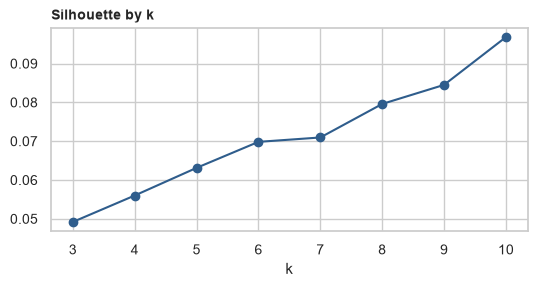

{3: 0.049, 4: 0.056, 5: 0.063, 6: 0.07, 7: 0.071, 8: 0.08, 9: 0.085, 10: 0.097}


In [17]:
NOISE = {'customer', 'states', 'state', 'reports', 'report', 'advise', 'check', 'please', 'concern', 'vehicle', 'car', 'truck', 'ro', 'dealer', 'tech', 'technician', 'time', 'times', 'verified', 'verify',
         'performed', 'found', 'tac', 'case', 'wcc', 'claim', 'code', 'codes', 'warranty', 'per', 'doc', 'id', 'ok', 'good', 'tested', 'test', 'checked', 'diag', 'na', 'gm', 'sop', 'hours', 'labor', 'op', 'new', 'cs', 'issue', 'issues', 'problem'}
STOP = list(ENGLISH_STOP_WORDS | NOISE)
TOK = r'(?u)\b[a-z][a-z]+\b'

# --- K-Means on customer complaints: TF-IDF -> SVD(60) -> L2 normalise (cosine geometry) -> choose k by silhouette ---
tf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True, token_pattern=TOK)
X = tf.fit_transform(T['cust']); terms = np.array(tf.get_feature_names_out())
Z = normalize(TruncatedSVD(60, random_state=42).fit_transform(X))
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z)) for k in range(3, 11)}
plt.figure(figsize=(5.5, 3)); plt.plot(list(sil), list(sil.values()), marker='o', color=BASE); plt.title('Silhouette by k', loc='left', fontsize=10, fontweight='bold'); plt.xlabel('k'); plt.tight_layout(); save('10_silhouette.png')
print({k: round(v, 3) for k, v in sil.items()})

In [18]:
K = max(range(6, 11), key=lambda k: sil[k])   # best silhouette among interpretable sizes (6-10 groups); scores are all < 0.1 -> soft, overlapping structure (short texts)
km = KMeans(K, n_init=20, random_state=42).fit(Z); df['complaint_cluster'] = km.labels_
def top_terms(idx, n=8):
    w = np.asarray(X[idx].mean(axis=0)).ravel(); return ', '.join(terms[w.argsort()[::-1][:n]])
for c in range(K): print(f'C{c} (n={np.sum(km.labels_==c)}): {top_terms(km.labels_==c)}')

C0 (n=108): update, stays, message, radio stays, turning, failed, ordered, replace
C1 (n=299): does, sound, phone, work, shut, turn, volume, start
C2 (n=150): screen, radio screen, black, screen black, screen blank, blank, touch, touch screen
C3 (n=73): goes, screen goes, blank, goes blank, screen, goes black, radio screen, black
C4 (n=78): camera, camera inoperative, inoperative, backup camera, backup, rear, rear camera, view
C5 (n=51): inoperative, radio inoperative, xm radio, xm, bluetooth, sound, electrical, displays
C6 (n=28): card, sd, sd card, removed, card removed, error, message, card error
C7 (n=71): working, radio working, navigation, camera working, camera, entertainment navigation, audio entertainment, audio
C8 (n=60): display, radio display, black, display inoperative, display screen, sound, inoperative, screen
C9 (n=82): xm, xm radio, signal, loading, play, stations, work, sirius


In [19]:
# Manual labels are assigned AFTER reading the top terms and sample verbatims above (kept in a dict so the notebook is reproducible)
CLUSTER_NAMES = {0: 'Software-type glitches (demo mode, freezes, error messages)', 1: 'Mixed audio / phone / power-cycle complaints', 2: 'Black screen / touchscreen',
                 3: 'Screen intermittently blank', 4: 'Backup camera inoperative', 5: 'Terse "radio inoperative" reports', 6: 'SD card / media errors',
                 7: 'Generic "not working" (camera, nav, speaker)', 8: 'Display inoperative / flashing', 9: 'XM / SiriusXM signal & streaming'}
df['complaint_cluster_name'] = df.complaint_cluster.map(lambda c: CLUSTER_NAMES.get(c, f'Cluster {c}'))

In [20]:
# --- LDA on technician narrative (counts, not tf-idf, as LDA expects) ---
LDA_STOP = STOP + ['radio', 'replaced', 'replace', 'replacement', 'program', 'programmed', 'programming', 'removed', 'installed', 'advised', 'called', 'contacted', 'operation', 'designed', 'working', 'unit', 'assembly']   # ubiquitous repair words hide the differences between topics
cv = CountVectorizer(stop_words=LDA_STOP, ngram_range=(1, 2), min_df=8, max_df=0.4, token_pattern=TOK)
Wt = cv.fit_transform(T['causal'] + ' ' + T['corr']); wterms = np.array(cv.get_feature_names_out())
NT = 6; lda = LatentDirichletAllocation(NT, learning_method='batch', max_iter=40, random_state=42).fit(Wt)
df['topic'] = lda.transform(Wt).argmax(axis=1); df['topic_strength'] = lda.transform(Wt).max(axis=1)
for t in range(NT): print(f'T{t} (n={np.sum(df.topic==t)}): ' + ', '.join(wterms[lda.components_[t].argsort()[::-1][:10]]))

TOPIC_NAMES = {0: 'Camera / video & coax cabling', 1: 'Media (SD/USB/nav) & programming errors', 2: 'Power / ground / data-line diagnostics', 3: 'Shorted module & Ethernet comm faults',
               4: 'Internal radio hardware failure', 5: 'Software update / USB reprogramming (XM, antenna)'}
df['topic_name'] = df.topic.map(TOPIC_NAMES)
# stability + agreement: are the clusters reproducible, and do they line up with the coded / mined labels?
base = df.complaint_cluster.values; from sklearn.metrics import adjusted_rand_score
print('K-Means stability (ARI vs 4 other seeds):', [round(adjusted_rand_score(base, KMeans(K, n_init=20, random_state=s).fit_predict(Z)), 2) for s in (1, 2, 3, 4)])
for lab in ['symptom_area', 'COMPLAINT_CD_DESC', 'issue_category', 'cause_mode']: print(f'NMI complaint_cluster vs {lab:18s}: {normalized_mutual_info_score(base, df[lab]):.2f}   | topic vs {lab}: {normalized_mutual_info_score(df.topic, df[lab]):.2f}')

T0 (n=124): camera, communication, cable, video, module, coax, rear, end, software, sps
T1 (n=124): usb, card, sd, sd card, screen, sps, error, told, sps usb, navigation
T2 (n=190): module, power, ground, update, circuit, circuits, power ground, control, data, communication
T3 (n=152): display, shorted, ethernet, reset, controls, audio, inoperative, scanned, assistance, comm
T4 (n=218): internal, fault, failure, internal fault, screen, internal failure, display, module, connection, malfunction
T5 (n=192): usb, xm, transfer, file, usb file, file transfer, update, sps, software, antenna
K-Means stability (ARI vs 4 other seeds): [0.56, 0.46, 0.48, 0.51]
NMI complaint_cluster vs symptom_area      : 0.40   | topic vs symptom_area: 0.08
NMI complaint_cluster vs COMPLAINT_CD_DESC : 0.05   | topic vs COMPLAINT_CD_DESC: 0.03
NMI complaint_cluster vs issue_category    : 0.01   | topic vs issue_category: 0.02
NMI complaint_cluster vs cause_mode        : 0.05   | topic vs cause_mode: 0.04


*Reading this:* complaint clusters line up strongly with the **symptom area** (what the customer sees) but hardly at all with **issue category** (what the technician finds) — i.e. the *same* visible symptom (black screen, camera out, XM loss) is produced by different underlying causes, so symptom text alone cannot triage root cause. This is why the root-cause view (LDA on technician text + coded cause) is needed.

In [21]:
def overindex(sub, col, minn=8, thr=1.3):
    a = sub[col].value_counts(); b = df[col].value_counts(normalize=True); lift = (a/len(sub)).div(b).dropna(); lift = lift[(a >= minn) & (lift >= thr)].sort_values(ascending=False)
    return f'{lift.index[0]} ({lift.iloc[0]:.1f}x)' if len(lift) else '-'
def profile(col, namecol, terms_fn):
    rows = []
    for g, sub in df.groupby(col):
        rows.append({'id': g, 'name': sub[namecol].iloc[0], 'events': len(sub), '%': round(len(sub)/len(df)*100, 1), 'top_terms': terms_fn(g),
                     'top_symptom_area': sub.symptom_area.value_counts().index[0], 'top_issue_category': f"{sub.issue_category.value_counts().index[0]} ({sub.issue_category.value_counts(normalize=True).iloc[0]:.0%})",
                     'top_cause_code': f"{sub.cause_mode.value_counts().index[0]} ({sub.cause_mode.value_counts(normalize=True).iloc[0]:.0%})",
                     'replaced_%': round(sub.tag_fix_condition.map(lambda l: 'Replaced' in l).mean()*100), 'median_days_in_service': sub.days_in_service.median(),
                     'over-indexed_plant': overindex(sub, 'BUILD_PLANT_DESC'), 'over-indexed_model': overindex(sub, 'MODEL')})
    return pd.DataFrame(rows)
cprof = profile('complaint_cluster', 'complaint_cluster_name', lambda g: top_terms(km.labels_ == g, 6)); display(cprof.drop(columns='id'))
tprof = profile('topic', 'topic_name', lambda g: ', '.join(wterms[lda.components_[g].argsort()[::-1][:8]])); display(tprof.drop(columns='id'))

,name,events,%,top_terms,top_symptom_area,top_issue_category,top_cause_code,replaced_%,median_days_in_service,over-indexed_plant,over-indexed_model
0,"Software-type glitches (demo mode, freezes, error messages)",108,10.8,"update, stays, message, radio stays, turning, failed",Radio / Head Unit (general),Communication / Network Fault (40%),No/Incorrect Communication (44%),86,303.0,Lansing Delta (1.4x),NebulaJet (1.6x)
1,Mixed audio / phone / power-cycle complaints,299,29.9,"does, sound, phone, work, shut, turn",Radio / Head Unit (general),Component Failure (internal) (37%),No/Incorrect Communication (43%),88,214.0,-,GalacticRoamer (1.5x)
2,Black screen / touchscreen,150,15.0,"screen, radio screen, black, screen black, screen blank, blank",Display / Screen,Component Failure (internal) (39%),No/Incorrect Communication (41%),89,270.0,-,InfernoSprint (3.5x)
3,Screen intermittently blank,73,7.3,"goes, screen goes, blank, goes blank, screen, goes black",Display / Screen,Component Failure (internal) (42%),No/Incorrect Communication (45%),88,228.5,-,ElectroStreak (1.8x)
4,Backup camera inoperative,78,7.8,"camera, camera inoperative, inoperative, backup camera, backup, rear",Camera / Rear Vision,Component Failure (internal) (40%),No/Incorrect Communication (44%),91,238.0,Spring Hill - Truck (1.4x),StellarGlide (2.9x)
5,"Terse ""radio inoperative"" reports",51,5.1,"inoperative, radio inoperative, xm radio, xm, bluetooth, sound",Radio / Head Unit (general),Component Failure (internal) (45%),No/Incorrect Communication (43%),96,173.0,Lansing Delta (1.5x),-
6,SD card / media errors,28,2.8,"card, sd, sd card, removed, card removed, error",USB / SD / Media,Component Failure (internal) (50%),No/Incorrect Communication (29%),89,190.0,Silao (1.6x),-
7,"Generic ""not working"" (camera, nav, speaker)",71,7.1,"working, radio working, navigation, camera working, camera, entert...",Navigation,Component Failure (internal) (42%),No/Incorrect Communication (37%),89,246.5,Flint (1.6x),FusionNova (2.1x)
8,Display inoperative / flashing,60,6.0,"display, radio display, black, display inoperative, display screen...",Display / Screen,Component Failure (internal) (38%),No/Incorrect Communication (40%),92,170.0,Spring Hill - Truck (1.5x),HyperFury X (1.8x)
9,XM / SiriusXM signal & streaming,82,8.2,"xm, xm radio, signal, loading, play, stations",Satellite Radio (XM),Communication / Network Fault (48%),No/Incorrect Communication (52%),89,168.0,Lansing Delta (1.4x),ShadowPulse (2.2x)


,name,events,%,top_terms,top_symptom_area,top_issue_category,top_cause_code,replaced_%,median_days_in_service,over-indexed_plant,over-indexed_model
0,Camera / video & coax cabling,124,12.4,"camera, communication, cable, video, module, coax, rear, end",Camera / Rear Vision,Communication / Network Fault (39%),No/Incorrect Communication (49%),90,213.0,Ramos Arizpe (1.7x),StellarGlide (1.8x)
1,Media (SD/USB/nav) & programming errors,124,12.4,"usb, card, sd, sd card, screen, sps, error, told",Display / Screen,Component Failure (internal) (45%),No/Incorrect Communication (37%),90,216.0,-,FusionNova (2.1x)
2,Power / ground / data-line diagnostics,190,19.0,"module, power, ground, update, circuit, circuits, power ground, co...",Display / Screen,Communication / Network Fault (39%),No/Incorrect Communication (43%),86,269.0,-,-
3,Shorted module & Ethernet comm faults,152,15.2,"display, shorted, ethernet, reset, controls, audio, inoperative, s...",Display / Screen,Component Failure (internal) (43%),No/Incorrect Communication (37%),90,231.0,-,TurboFlare (1.4x)
4,Internal radio hardware failure,218,21.8,"internal, fault, failure, internal fault, screen, internal failure...",Display / Screen,Component Failure (internal) (49%),No/Incorrect Communication (41%),92,220.0,-,SolarStriker (1.6x)
5,"Software update / USB reprogramming (XM, antenna)",192,19.2,"usb, xm, transfer, file, usb file, file transfer, update, sps",Satellite Radio (XM),Communication / Network Fault (42%),No/Incorrect Communication (48%),87,207.5,-,GalacticRoamer (1.7x)


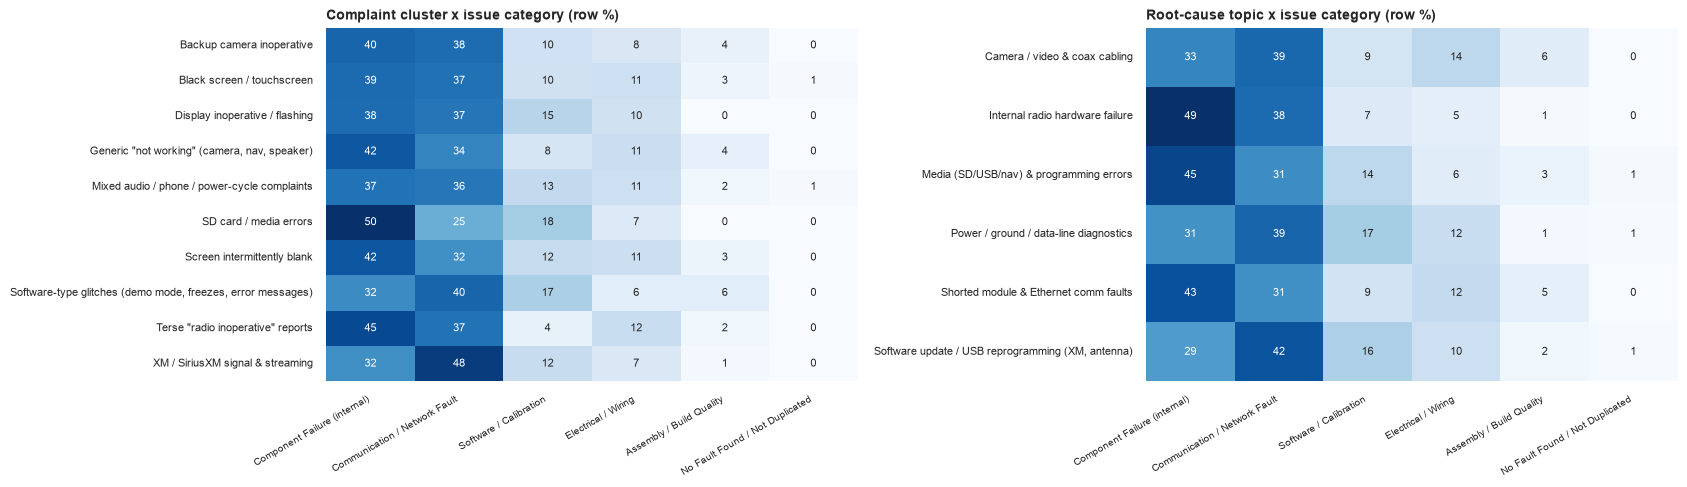

cause_mode,No/Incorrect Communication,Shorted,Registers Incorrectly,Broken,Campaign/ Tech Bulletin,Follow operation
topic_name,,,,,,
Camera / video & coax cabling,56.0,24.0,11.0,6.0,1.0,2.0
Internal radio hardware failure,43.0,33.0,13.0,8.0,1.0,2.0
Media (SD/USB/nav) & programming errors,42.0,27.0,23.0,4.0,2.0,3.0
Power / ground / data-line diagnostics,47.0,27.0,16.0,5.0,2.0,2.0
Shorted module & Ethernet comm faults,41.0,40.0,10.0,4.0,1.0,3.0
"Software update / USB reprogramming (XM, antenna)",53.0,20.0,16.0,3.0,6.0,3.0


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, col, ttl in [(ax[0], 'complaint_cluster_name', 'Complaint cluster x issue category (row %)'), (ax[1], 'topic_name', 'Root-cause topic x issue category (row %)')]:
    ct = pd.crosstab(df[col], df.issue_category).reindex(columns=CATS); sns.heatmap(ct.div(ct.sum(axis=1), axis=0)*100, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=a, annot_kws={'size': 8})
    a.set_title(ttl, loc='left', fontsize=10, fontweight='bold'); a.set_ylabel(''); a.set_xlabel(''); plt.setp(a.get_xticklabels(), rotation=30, ha='right', fontsize=7); plt.setp(a.get_yticklabels(), fontsize=8)
plt.tight_layout(); save('11_cluster_heatmaps.png')
tc = pd.crosstab(df.topic_name, df.cause_mode).loc[:, df.cause_mode.value_counts().head(6).index]; display((tc.div(tc.sum(axis=1), axis=0)*100).round(0))

### 3e. Root-cause synthesis
Evidence from the coded cause, the mined tags and the clusters/topics is combined below (counts are computed live from the data).

In [23]:
n = len(df); rep = df.tag_fix_condition.map(lambda l: 'Replaced' in l); prog = df.tag_fix_condition.map(lambda l: 'Programmed' in l)
facts = {
 'events': n, 'radio_replaced_%': round(rep.mean()*100, 1), 'replace+program_%': round((rep & prog).mean()*100, 1), 'program_only_%': round((prog & ~rep).mean()*100, 1),
 'internal_fault_%': round(df.tag_diagnosis.map(lambda l: 'Internal Fault' in l).mean()*100, 1), 'lost_comm_text_%': round(df.tag_diagnosis.map(lambda l: 'Lost Communication' in l).mean()*100, 1),
 'tac_contacted_%': round(df.tag_process.map(lambda l: 'TAC / Engineering Contacted' in l).mean()*100, 1), 'no_dtc_%': round((df.dtc_status == 'No DTC Found').mean()*100, 1),
 'intermittent_%': round(df.tag_additional_context.map(lambda l: 'Intermittent' in l).mean()*100, 1), 'within_90d_%': round((df.days_in_service <= 90).mean()*100, 1),
 'module_component_code_%': round((df.cause_system == 'Module/Component').mean()*100, 1), 'wiring_code_%': round((df.cause_system == 'Wiring/Electrical/Sensors').mean()*100, 1),
 'non_english_%': round((df.language != 'en').mean()*100, 1), 'repeat_visit_%': round(df.tag_process.map(lambda l: 'Repeat Visit' in l).mean()*100, 1)}
display(pd.Series(facts).to_frame('value'))
mt = df[df.MAKE.isin(df.MAKE.value_counts().index)].groupby('MAKE').agg(events=('Event id', 'size'), replaced_pct=('tag_fix_condition', lambda s: round(s.map(lambda l: 'Replaced' in l).mean()*100)), median_days=('days_in_service', 'median')); display(mt)

,value
events,1000.0
radio_replaced_%,89.0
replace+program_%,66.2
program_only_%,8.4
internal_fault_%,33.9
lost_comm_text_%,16.9
tac_contacted_%,29.5
no_dtc_%,18.0
intermittent_%,20.2
within_90d_%,19.5


,events,replaced_pct,median_days
MAKE,,,
NebulaCruiser,125,85,269.5
NovaSprint,335,88,215.0
ThunderVolt,488,91,220.0
TurboFlux,52,88,276.5


---
## 4. Export — tagged dataset
The six original tag columns (`Trigger … Fix Condition`) are now **populated for all 1,000 events** with the mined tags (same list format as the examples). Extra columns hold symptoms, diagnosis, process flags, DTC status, issue category, symptom area, cluster and topic. The Excel workbook colour-codes the headers (grey = original data, green = extracted tags, blue = classification/model outputs), highlights the five provided example rows, and adds dictionary / frequency / profile / validation sheets.

In [24]:
ORIG = {'Trigger': 'tag_trigger', 'Failure Component': 'tag_failure_component', 'Failure Condition': 'tag_failure_condition',
        'Additional Context': 'tag_additional_context', 'Fix Component': 'tag_fix_component', 'Fix Condition': 'tag_fix_condition'}
out = df.copy()
for o, m in ORIG.items(): out[o] = out[m].map(str)                                    # e.g. "['Radio', 'SPS']" - identical format to the provided examples
out['Symptoms (mined)'] = out.tag_symptom.map(str); out['Diagnosis (mined)'] = out.tag_diagnosis.map(str); out['Process Flags'] = out.tag_process.map(str)
out['Provided example row'] = out['Event id'].isin(gold.index)
out['Data quality flags'] = np.select([out.date_anomaly & out.in_use_imputed, out.date_anomaly, out.in_use_imputed], ['opened<in_service; in_service imputed', 'opened<in_service (days blank)', 'in_service imputed'], '')
ORIGINAL_COLS = ['Event id', 'opened', 'build', 'in_use', 'MAKE', 'MODEL', 'BUILD_PLANT_DESC', 'COMPLAINT_CD_DESC', 'CAUSAL_CD_DESC', 'CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM']
TAG_COLS = list(ORIG) + ['Symptoms (mined)', 'Diagnosis (mined)', 'Process Flags', 'dtc_status']
CLASS_COLS = ['issue_category', 'symptom_area', 'complaint_cluster_name', 'topic_name', 'language', 'days_in_service', 'Provided example row', 'Data quality flags']
final = out[ORIGINAL_COLS + TAG_COLS + CLASS_COLS].rename(columns={'opened': 'Opened date', 'build': 'Build date', 'in_use': 'In-service date', 'dtc_status': 'DTC status', 'issue_category': 'Issue category',
        'symptom_area': 'Symptom area', 'complaint_cluster_name': 'Complaint cluster', 'topic_name': 'Root-cause topic', 'language': 'Language', 'days_in_service': 'Days in service'})
TAG_COLS_NICE = set(TAG_COLS) - {'dtc_status'} | {'DTC status'}; CLASS_NICE = {'Issue category', 'Symptom area', 'Complaint cluster', 'Root-cause topic', 'Language', 'Days in service', 'Provided example row', 'Data quality flags'}
final.to_csv(OUT + 'Hanuai_task2_tagged.csv', index=False, encoding='utf-8-sig')

# --- supporting sheets ---
ENT_NAME = {'failure_component': 'Failure Component', 'failure_condition_symptom': 'Failure Condition (symptom)', 'diagnosis': 'Failure Condition (diagnosis)', 'trigger': 'Trigger',
            'context': 'Additional Context', 'fix_component': 'Fix Component', 'fix_condition': 'Fix Condition', 'process': 'Process Flag'}
dictionary = pd.DataFrame([(ENT_NAME[e], t, ' > '.join('+'.join(g) for g in SPEC[e]), p[:250]) for e, v in VOCAB.items() for t, p in v.items()], columns=['entity type', 'tag', 'source text (cascade order)', 'regex (normalised text)'])
freq = pd.concat([out[c].explode().value_counts().rename_axis('tag').reset_index(name='events').assign(**{'entity type': n, '% of events': lambda d: (d.events/len(out)*100).round(1)})
                  for c, n in [('tag_failure_component', 'Failure Component'), ('tag_symptom', 'Symptom'), ('tag_diagnosis', 'Diagnosis'), ('tag_trigger', 'Trigger'), ('tag_additional_context', 'Additional Context'),
                               ('tag_fix_component', 'Fix Component'), ('tag_fix_condition', 'Fix Condition'), ('tag_process', 'Process Flag')]])[['entity type', 'tag', 'events', '% of events']]
catsum = df.groupby('issue_category').agg(events=('Event id', 'size'), median_days_in_service=('days_in_service', 'median'), replaced_pct=('tag_fix_condition', lambda s: round(s.map(lambda l: 'Replaced' in l).mean()*100)),
                                        top_cause_code=('cause_mode', lambda s: s.value_counts().index[0]), top_symptom_area=('symptom_area', lambda s: s.value_counts().index[0])).sort_values('events', ascending=False)
catsum['% of events'] = (catsum.events/len(df)*100).round(1); catsum = catsum.reset_index()
goldval = V.assign(gold=V.gold.map(', '.join), mine=V.mine.map(', '.join))[['event', 'field', 'gold', 'mine', 'tp', 'n_gold', 'n_mine']]
readme = pd.DataFrame({'sheet': ['Tagged_Data', 'Tag_Dictionary', 'Tag_Frequency', 'Category_Summary', 'Cluster_Profile', 'Topic_Profile', 'Gold_Validation'],
                       'content': ['All 1,000 events: cleaned original fields (grey headers), extracted tags (green), classifications / clusters (blue). Yellow rows = the 5 provided example rows.',
                                   'Every tag with its search pattern and source text (customer / causal / correction) and cascade order', 'How often each tag occurs (multi-label, % of events)',
                                   'Issue categories with volume, time-to-claim, replacement rate', 'K-Means complaint clusters: top terms, dominant category, cause code, plant/model concentration',
                                   'LDA root-cause topics: top terms and dominant category / cause code', 'Extracted tags vs the 5 provided example rows']})
with pd.ExcelWriter(OUT + 'Hanuai_task2_tagged.xlsx', engine='openpyxl') as xw:
    readme.to_excel(xw, sheet_name='README', index=False)
    final.to_excel(xw, sheet_name='Tagged_Data', index=False)
    for name, d in [('Tag_Dictionary', dictionary), ('Tag_Frequency', freq), ('Category_Summary', catsum), ('Cluster_Profile', cprof.drop(columns='id')), ('Topic_Profile', tprof.drop(columns='id')), ('Gold_Validation', goldval)]: d.to_excel(xw, sheet_name=name, index=False)
    from openpyxl.styles import PatternFill, Font, Alignment
    fills = {'orig': PatternFill('solid', fgColor='D9D9D9'), 'tag': PatternFill('solid', fgColor='C6E0B4'), 'cls': PatternFill('solid', fgColor='BDD7EE'), 'hdr': PatternFill('solid', fgColor='D9D9D9'), 'gold': PatternFill('solid', fgColor='FFF2CC')}
    for name, ws in xw.sheets.items():
        ws.freeze_panes = 'B2' if name == 'Tagged_Data' else 'A2'; ws.auto_filter.ref = ws.dimensions
        for j, cell in enumerate(ws[1]):
            col = cell.value; cell.font = Font(bold=True); cell.alignment = Alignment(vertical='center', wrap_text=True)
            cell.fill = fills['tag'] if (name == 'Tagged_Data' and col in TAG_COLS_NICE) else fills['cls'] if (name == 'Tagged_Data' and col in CLASS_NICE) else fills['orig']
            width = 18 if name == 'Tagged_Data' else 28; ws.column_dimensions[cell.column_letter].width = 55 if col in ('CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM', 'regex (normalised text)', 'content', 'top_terms') else width
        if name == 'Tagged_Data':
            flag = [c.value for c in ws[1]].index('Provided example row') + 1
            for row in ws.iter_rows(min_row=2):
                if row[flag-1].value: [setattr(c, 'fill', fills['gold']) for c in row]
            ws.row_dimensions[1].height = 32
print('Saved:', [f for f in os.listdir(OUT) if f.startswith('Hanuai')], '| rows:', len(final), '| columns:', final.shape[1])

Saved: ['Hanuai_task2_tagged.csv', 'Hanuai_task2_tagged.xlsx'] | rows: 1000 | columns: 30


---
## 5. Conclusions
### Key findings (n = 1,000 infotainment events)
1. **The head unit is the failure point.** 89 % of events end with a radio replacement (66 % *replace + reprogram*); only 8 % were fixed by reprogramming alone. 71 % of complaints mention the radio, 37 % the display, 12 % XM and 12 % the rear camera.
2. **Failure mode:** coded cause is 82 % *Module/Component* and 9 % *Wiring/Electrical*. Top modes: *No/Incorrect Communication* (38 %), *Shorted* (24 %), *Registers Incorrectly* (12 %). Mined text agrees: *internal fault/failure* appears in 34 % of narratives and *lost communication / Ethernet / data link* in 17 %.
3. **Issue categories:** Component failure 38 %, Communication/Network 37 %, Software/Calibration 12 %, Electrical/Wiring 10 %, Assembly/Build quality 3 %, No-fault-found < 1 %.
4. **Customer symptoms:** inoperative (32 %), black/blank screen (25 %), random shutdown/reboot (12 %), no sound (11 %); 20 % are intermittent; 18 % explicitly record *no DTC found*; 30 % needed TAC/engineering escalation (diagnosis is costly).
5. **Early-life failures:** 20 % of claims occur within 90 days of in-service and 39 % within 180 days (median ≈ 228 days). Time-to-claim does not differ significantly by category (Kruskal-Wallis p = 0.35).
6. **Stable over time, weak segment effects:** category mix is statistically unchanged across the claim window (χ² p = 0.30); the only notable drift is Communication/Network share −7.6 pp (p = 0.052). Plant (p = 0.49), make (p = 0.15) and model (p = 0.07) show only weak association with category (Cramér's V ≤ 0.11) — **no strong evidence of a plant-specific defect**; model-level hints (HyperFury X/TurboFlare electrical, NebulaJet communication, n = 15–37) are watch-list items, not conclusions.
7. **Clusters:** complaints form soft, overlapping groups (silhouette ≤ 0.10, seed-to-seed ARI ≈ 0.45–0.57). They map to *symptom area* (NMI 0.40) but not to *issue category* (NMI 0.01): identical symptoms hide different mechanisms. The *software-type glitches* cluster (demo mode, freezes, error messages) is the slowest to surface (median 303 days) and over-indexes at Lansing Delta (1.4×).

### Potential root causes (hypotheses to verify)
| Hypothesis | Evidence in this data | How to confirm |
|---|---|---|
| Radio internal electronics / power-stage short | *Shorted* code 24 %, *internal fault* text 34 %, 89 % replaced | Teardown + failure analysis of returned radios; supplier 8D |
| Ethernet/CAN communication interface failure | *No/Incorrect Communication* 38 % + text (*ethernet, data link, lost comm*) | Bus-level diagnostics on returned units; correlate with firmware/hardware revision |
| Software defects / outdated calibration | 8 % program-only fixes, 12 % software category, *demo mode/freeze* cluster, bulletins referenced in 5 % | Compare software versions pre/post update; OTA pilot |
| Wiring / connector / antenna-coax issues | *Wiring/Electrical* code 9 %, *Wiring Fault* text 3 %, camera/coax topic | Harness inspection, terminal-fretting checks (dielectric grease guidance appears in tech notes) |
| Assembly/handling (loose, not clipped, routing) | 3 % of events, concentrated in specific codes | Line audit at build plants once volumes are available |

### Limitations
No production/sales denominators (shares ≠ failure rates), no cost data, one model year, right-censored recent months, 7.6 % invalid date pairs, regex lexicon not exhaustive, validation on only 5 labelled rows, weak cluster separation.

### Key technical learnings & next steps
* **Lexicon + regex tagging is transparent and fast but brittle** → label ~300 events, fine-tune a small transformer NER / use an open-source LLM (e.g. Llama / Qwen with JSON-schema prompting) and measure F1 against the lexicon baseline.
* **Short, noisy, multilingual text gives low silhouette** → try multilingual sentence embeddings + BERTopic/HDBSCAN; keep K-Means/LDA as interpretable baselines.
* **Coded fields beat text for category assignment, text beats codes for nuance** (e.g. *Registers Incorrectly*, *Follow operation*) → combine both, as done here.
* Add **production volumes + build-lot/supplier lot** → convert counts to ppm/1000-vehicles, run survival (Weibull) and control-chart (p-chart/CUSUM) analysis for early-warning.
* Mandate **structured capture** at the dealer (pick-lists for symptom/trigger/fix, retained DTC codes, valid date checks) so mining is a safety net rather than the primary source.